In [1]:
import scanpy as sc
import scanpy.external as sce
import spatialdata as sd
import squidpy as sq
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from tqdm.auto import tqdm
import os
import sys
import spatialdata_io as sio
import spatialdata_plot

from skimage.color import rgb2lab, lab2rgb
from matplotlib.colors import to_rgb, to_hex

def generate_contrasting_colors(existing_colors, n, return_type = 'rgb',candidates=5000, seed=0):
    """
    Parameters
    ----------
    existing_colors : list
        List of matplotlib-compatible colors (hex, names, RGB tuples).
    n : int
        Number of new colors to generate.
    return_type ['rgb','hex']
    candidates : int
        Number of random candidate colors.
    seed : int or None

    Returns
    -------
    list
        List of hex colors.
    """
    print (existing_colors)
    print (n)
    rng = np.random.default_rng(seed)

    # Convert existing colors to Lab
    rgb = np.array([to_rgb(c) for c in existing_colors]).reshape(-1, 1, 3)
    existing_lab = rgb2lab(rgb).reshape(-1, 3)

    # Generate candidate colors in HSV
    h = rng.random(candidates)
    s = rng.uniform(0.55, 0.90, candidates)
    v = rng.uniform(0.65, 0.95, candidates)

    import colorsys
    candidate_rgb = np.array([colorsys.hsv_to_rgb(*x) for x in zip(h, s, v)])

    candidate_lab = rgb2lab(candidate_rgb.reshape(-1, 1, 3)).reshape(-1, 3)

    selected = []

    for _ in range(n):
        if len(selected):
            current = np.vstack([existing_lab] + selected)
        else:
            current = existing_lab

        # Compute squared Lab distances
        diff = candidate_lab[:, None, :] - current[None, :, :]
        dist2 = np.sum(diff**2, axis=2)

        # Distance to nearest existing/selected color
        score = dist2.min(axis=1)

        best = np.argmax(score)

        selected.append(candidate_lab[best:best+1])

        # Remove chosen candidate
        candidate_lab = np.delete(candidate_lab, best, axis=0)
        candidate_rgb = np.delete(candidate_rgb, best, axis=0)

    # Convert selected Lab back to RGB
    selected_lab = np.vstack(selected)
    rgb = lab2rgb(selected_lab.reshape(-1, 1, 3)).reshape(-1, 3)
    rgb = np.clip(rgb, 0, 1)
    if return_type=='rgb':
        return rgb
    if return_type=='hex':
        return [to_hex(i) for i in rgb]
def resolve_color_dict(unique_classes,color_dict,return_type='rgb'):
    from matplotlib.colors import to_rgb,to_hex
    
    
    color_dict = {k:to_rgb(v) for k,v in color_dict.items()}
    noncolored_classes = [i for i in unique_classes if i not in color_dict]
    if len(noncolored_classes)>0:
        new_colors = generate_contrasting_colors(color_dict.values(),len(noncolored_classes),
                                                return_type=return_type)
        color_dict = {**color_dict,**{n:c for n,c in zip(noncolored_classes,new_colors)}}
    if return_type=='rgb':
        color_function=lambda x: tuple([int(255*i) for i in x])
    elif return_type=='hex':
        color_function=to_hex
        
    color_dict = {k:color_function(v) for k,v in color_dict.items()}
                      
    return color_dict

def export_samp_cells(samp_xen,col_name,
                      tag,
                      color_dict = {},
                      root = './Xenium/annotations_export/',
                     filename='{}_{}cellannotations.csv'):
    """
    tag: prefix for celltype annotation
    """
    from matplotlib.colors import rgb2hex
    unique_classes = list(samp_xen[col_name].unique())
    color_dict = resolve_color_dict(unique_classes,color_dict,return_type='hex')
    df = samp_xen.loc[:,['cell_id',col_name]].rename(columns = {col_name:'group'})
    df['color'] = [color_dict[i] for i in df['group'].values]
    df.to_csv(os.path.join(root,filename.format(samp_xen.name,tag)),index=False,
             index_label=False
             )
    
def create_geoJSON_selection(pointsxy,name,color,class_name):
    import uuid


    j = {
      "type": "Feature",
      "id": str(uuid.uuid4()),
      "geometry": {
        "type": "Polygon",
        "coordinates": 
          [[[int(i/0.2125),int(j/0.2125)] for i,j in pointsxy
        ]]
      },
      "properties": {
          "name":name,
        "objectType": "annotation",
          "color":color,
        "classification": {
          "name": class_name,
          "color": color
        }
      }
    }
    return j
def create_geoJSON_fromselectionlist(selectionlist):
    j = {"type": "FeatureCollection",
          "features": selectionlist
     }
    return j




def generate_annots(alldata,col_name='Niche label',color_dict = {},color_type='rgb',
                   root = '../annotations_export/',
                    filename = '{}_niche_annotations.geojson'
                   ):
    
    import json
    from matplotlib.colors import rgb2hex,to_rgb
    unique_classes = alldata[col_name].unique()
    color_dict = resolve_color_dict(unique_classes,color_dict,return_type=color_type)
    
    
#     COLOR=(255,0,0)
    alldata['samp'] = [reg_to_samp_dict[index[1]] for index in alldata.index]

    for samp in alldata['samp'].unique():
        
        selection_list = []
        niche_data_df = alldata[alldata['samp']==samp]
        print('{} niche breakdown: {} total'.format(samp,len(niche_data_df)))
        display(niche_data_df[col_name].value_counts())
        for (condition,region,nicheid),row in tqdm(niche_data_df.iterrows()):
            nichemethod = row['niche method']
            crop = xen[xen.obs[nichemethod]==nicheid]
            hullpts = get_cellgroup_convex_hull(crop.obs.loc[:,['x','y']].values)
            if len(hullpts)<=3:
                continue
            class_name = row[col_name]
            selection_list+=[create_geoJSON_selection(hullpts,nicheid,color_dict[class_name],class_name)]
        geoJson_out = create_geoJSON_fromselectionlist(selection_list)
        
        with open(os.path.join(root,filename.format(samp)),'w') as f:
            json.dump(geoJson_out,f)
def mfi_normalize(df,scalar = .5,a_min = 0,a_max=3): 
    """df needs to be dataframe or else mean will be calulated only in rows where all columns are 0"""
    if type(df)!=pd.DataFrame:
        raise ValueError ("df must be dataframe")
    mn = df[df>0].mean()*scalar
    z = np.clip((df-mn.values)/mn,
                a_min=a_min,a_max=a_max)
    nacols = z.isnull().sum()
    nagenes = nacols[nacols>0].index
    z0 = z.fillna(0)
    return z0,nagenes

/home/nig060/miniconda3/envs/python3.10/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/nig060/miniconda3/envs/python3.10/lib/python3.10/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
/home/nig060/miniconda3/envs/python3.10/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, Fut

In [1]:
dc_genes=['Zbtb46', 'Cd24a', 'Fscn1', 'Bst2', 'Irf8', 'Clec9a', 
          'Xcr1', 'Batf3', 'Lamp3', 'Irf7','Itgae','Itgax' ,'Cd209a',
          'Irf4', 'Tlr7', 'Siglech', 'Ccr7', 'Ccl17', 'Ccl22']

dc_activation_genes=['Ccr7', 'Il12b', 'Cd40', 'Cd274', 
                     'Ido1', 'Il15', 'Cxcl10', 'Ccl5', 
                     'Cxcl9', 'H2-Aa', 'H2-Ab1', 'H2-K1', 
                     'H2-D1', 'B2m', 'Cd83', 'Ubd', 'Cd86', 
                     'Cd80', 'Icosl', 'Relb', 'Nfkbia', 'Ccl19', 
                     'Pdcd1lg2', 'Cxcl16', 'Ache','Birc3','Flt3','Icam1','Serpinb9']

stroma_genes=['Acta2', 'Pdgfra', 'Pdgfrb', 'Fap', 'Pdpn', 'Dcn', 'Cxcl12', 'Tgfb1', 'Postn']

tumor_genes=['Epcam', 'Cdh1', 'Cdh2', 'Snai2', 'Plekhs1', 'Krt5', 'Col17a1', 'Twist2', 'Cd44', 'Zeb1', 'Zeb2', 'Twist1', 'S100a4', 'Snai1', 'Col6a2', 'EGFP', 'mCherry']

isgs=['Oas2', 'Isg15', 'Ifit1']

ig_genes=['Prdm1', 'Xbp1', 'Jchain', 'Ighg1']

t_signature=['Cd3d', 'Cd3e', 'Cd4', 'Cd8a', 'Cd8b1', 'Trac', 'Cd247', 'Trbc1', 'Foxp3']

b_signature=['Ms4a1', 'Cd19', 'Cd79a', 'Pax5']

plasma_signature=[ 'Xbp1', 'Jchain', 'Ighg1']

monocyte_mac_sig=['Itgam', 'Adgre1', 'Cd68', 'Ccr2', 'Mrc1', 'Ly6c1', 'Nos2', 'Il1b', 'Il10', 'Il1a', 'Arg1']

neut_signature=['Mpo', 'Ly6g']

caf_sig=['Acta2', 'Pdgfra', 'Pdgfrb', 'Fap', 'Pdpn', 'Dcn', 'Cxcl12', 'Tgfb1', 'Postn']

endo_sig=['Pecam1', 'Kdr', 'Vwf', 'Selp', 'Ackr1', 'Jag1']

peri_sig=['Rgs5', 'Pdgfrb', 'Myh11', 'Rergl', 'Mgp', 'Ntrk2', 'Kcnj8']

tclustergenes=['Foxp3', 'Cxcr3', 'Cxcr4', 'Lag3', 'Klrk1', 'Gzma', 
               'Tnfrsf4', 'Cxcr5', 'Ccl3', 'Il2ra', 'Ctla4', 
               'Nr4a1', 'Tox', 'Tnf', 'Ccr4', 'Ccl4', 
               'Klrb1c', 'Il7r', 'Tnfrsf9', 
               'Chat', 'Eomes', 'Havcr2', 
               'Cxcr6', 'Cd40lg', 'Icos', 'Ccr7', 
               'Sell', 'Tcf7', 'Il2', 'Cd27', 'Cd69', 'Ccl2', 
               'Gzmb', 'Ccr5', 'Pdcd1', 'Ccl5', 'Ifng', 
               'Prf1', 'Tigit', 'Klrd1']

all_sigs = {'dc lineage':dc_genes,
            'dc activation':dc_activation_genes,
            'stroma':stroma_genes,'tumor':tumor_genes,'isgs':isgs,'ig':ig_genes,
't cell':t_signature,'t activation':tclustergenes,
            'b cell':b_signature,'plasma cell':plasma_signature,'mono/mac':monocyte_mac_sig,
'neutrophil':neut_signature,'caf':caf_sig,'endothelial cell':endo_sig,'pericyte':peri_sig}

In [2]:
xen =sc.read_h5ad('./Mouse_TME_CODEX/20260623__194743__graham_take2/usefuldata/2026_0710_chemoxeniumanndata')

In [ ]:
print("kernel responsive")

In [4]:
expr = xen.to_df() # Convert Xenium data to df
pseudocount = .1
cluster_sigs = {}
for name,sig in tqdm(all_sigs.items()): # z-score genes that are cluster markers in cluster signatures (stroma, tumor, ig, t cell, b cell, plasma cell...
    if name in ['isgs','dc lineage','dc activation','t activation']:
        continue
    pos = expr.loc[:,sig]
#     std = pos[pos>0].std()
    mn = pos[pos>0].mean()/2

    z = np.clip((pos-mn.values)/mn,
                a_min=0,a_max=3) # Scales enes between 0 and 3, where (mean of positive values)/2 = 0
    
    
    geo_mean_pos = np.exp(np.log(z + pseudocount).mean(axis=1))
    
    thresh = np.exp(np.log(1 + pseudocount).mean())
    cluster_sigs[name] = geo_mean_pos/thresh # Calculate cluster signatures for each signature name
df = pd.concat(cluster_sigs,axis=1)
sigs_ad = sc.AnnData(X =df)

  0%|          | 0/15 [00:00<?, ?it/s]

In [7]:
subs =sc.pp.subsample(sigs_ad,n_obs=10000,copy=True) #Subsample 10000 cells
sc.pp.pca(subs)
sc.pp.neighbors(subs,use_rep='X_pca')
sc.tl.leiden(subs)
sc.tl.umap(subs) # Run PCA and UMAP on subsample 

In [ ]:
subs.var_names

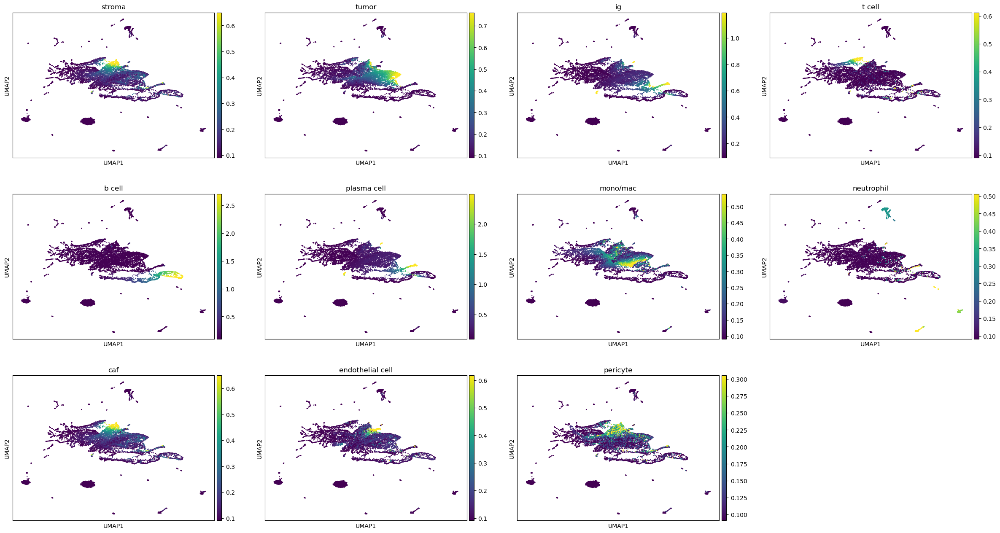

In [8]:
sc.pl.umap(subs,
#            color=['leiden'],
#            groups=['1','32','35'],
           
           color=subs.var_names,
#            vmin=.5,vmax=2
           vmin = 'p05',vmax='p99'
          )

In [9]:
subs.obs['Cell Type'] = xen.obs.loc[subs.obs_names,'Cell Type']

In [11]:
subs.obs.head()
norm_genesubset_subsample.obs_names[1:5]
norm_genesubset_subsample.obs.head()
norm_genesubset.obs_names[1:5]

NameError: name 'norm_genesubset_subsample' is not defined

/home/nig060/miniconda3/envs/python3.10/lib/python3.10/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


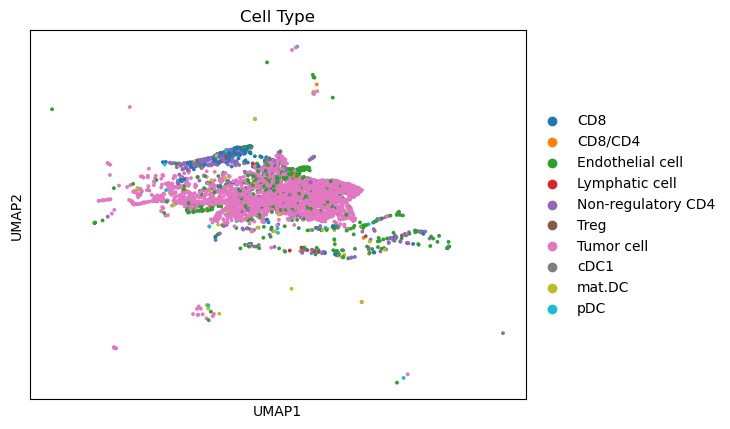

In [10]:
sc.pl.umap(subs[subs.obs['Cell Type']!='unknown'],
#            color=['leiden'],
#            groups=['1','32','35'],
           
           color=['Cell Type'],
#            vmin=.5,vmax=2
           vmin = 'p05',vmax='p99'
          )

In [11]:
cell_subset = xen[xen.obs['Cell Type']=='Tumor cell']

In [12]:
cell_subset.shape

(118128, 300)

In [13]:
cluster_genes = list(xen.var_names)#include all genes
#cluster_genes = list(set(all_sigs['tumor']+all_sigs['stroma']+all_sigs['caf']))

In [14]:
raw_all_genes = cell_subset

In [15]:
#raw_all_genes should be gene counts
leiden_cluster_all = True


raw_genesubset = raw_all_genes[:,cluster_genes].copy() 
norm_genesubset = sc.pp.normalize_total(raw_genesubset,
                                             copy=True) # Normalizes 

sc.pp.log1p(norm_genesubset) # Log-transform 
    
norm_genesubset_subsample = sc.pp.subsample(norm_genesubset,n_obs=10000,copy=True) # Subsamples 

if leiden_cluster_all: # Run neighbors and Leiden cluster on every cell
    sc.pp.neighbors(norm_genesubset)
    sc.tl.leiden(norm_genesubset, resolution=.1)
else:
    sc.pp.neighbors(norm_genesubset_subsample)
    sc.tl.leiden(norm_genesubset_subsample,resolution=.1)

sc.pp.neighbors(norm_genesubset_subsample)
sc.tl.umap(norm_genesubset_subsample,min_dist=.1)


#if you picked a subset of genes,you need to create a new anndata with all genes and copy the leiden and umap info into it
raw_aligned = raw_all_genes[norm_genesubset_subsample.obs_names] # All genes for subsample 
raw_aligned.obsm['X_umap'] = norm_genesubset_subsample.obsm['X_umap']
if leiden_cluster_all:
    l=norm_genesubset.obs.loc[norm_genesubset_subsample.obs_names]['leiden'] # Get Leiden information for the subsample from the whole dataset
else:
    l =norm_genesubset_subsample.obs['leiden']

raw_aligned.obs['leiden'] = l

/home/nig060/miniconda3/envs/python3.10/lib/python3.10/site-packages/scanpy/neighbors/__init__.py:577: UserWarning: You’re trying to run this on 300 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.
  x = _choose_representation(self._adata, use_rep=use_rep, n_pcs=n_pcs)
/home/nig060/miniconda3/envs/python3.10/lib/python3.10/site-packages/scanpy/neighbors/__init__.py:577: UserWarning: You’re trying to run this on 300 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.
  x = _choose_representation(self._adata, use_rep=use_rep, n_pcs=n_pcs)
/tmp/ipykernel_987626/3722910073.py:26: ImplicitModificationWarning: Setting element `.obsm['X_umap']` of view, initializing view as actual.
  raw_aligned.obsm['X_umap'] = norm_genesubset_subsample.obsm['X_umap']


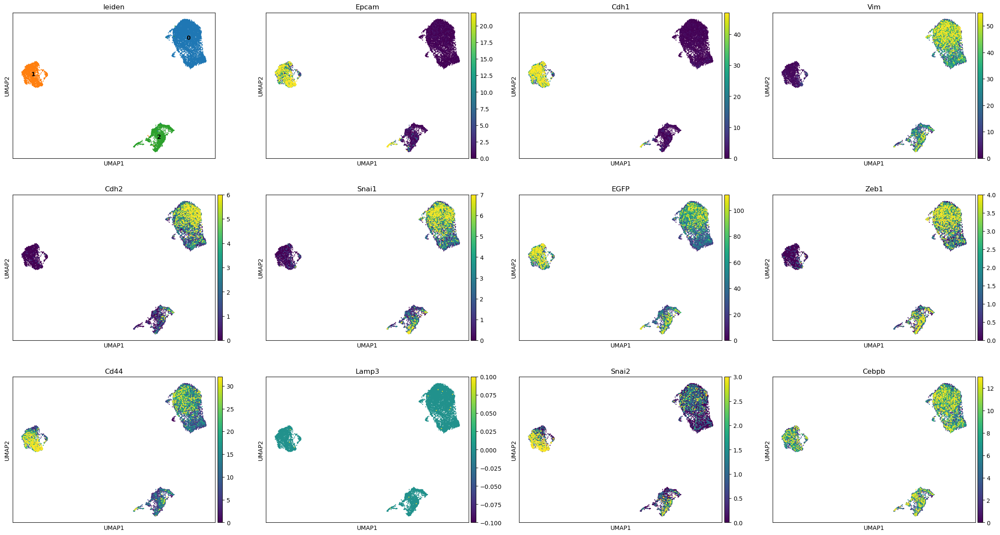

In [16]:
sc.pl.umap(raw_aligned,color=['leiden',
                'Epcam','Cdh1','Vim','Cdh2','Snai1','EGFP','Zeb1','Cd44','Lamp3','Snai2','Cebpb'
#     'Cxcl10'
                ],
           legend_loc='on data',
           vmin=0,vmax='p95') # Clearly 3 clusters: Epi, Mes, pEMT

In [17]:
xen.obs.loc[norm_genesubset.obs_names,'tumor cell leiden'] = norm_genesubset.obs['leiden']

In [63]:
xen[~xen.obs['tumor cell leiden'].isnull()].obs.groupby('samp').apply(export_samp_cells,
                           'tumor cell leiden',
                                tag='tumorcelltype v1',
                               color_dict = {'3':'red',
                               '4':'red',
                               '12':'red'})

dict_values([(1.0, 0.0, 0.0), (1.0, 0.0, 0.0), (1.0, 0.0, 0.0)])
11
dict_values([(1.0, 0.0, 0.0), (1.0, 0.0, 0.0), (1.0, 0.0, 0.0)])
11


""


In [20]:
# Let's get which genes are DE between (5,7,8,9) and Mes (0,1,3,4,11,12,13) clusters
sc.tl.rank_genes_groups(
    norm_genesubset,
    groupby="leiden",
    groups=["5","7","8","9"],
    reference="rest",
    method="wilcoxon"   # or "t-test", "logreg"
)
de = sc.get.rank_genes_groups_df(norm_genesubset, group=["5","7","8","9"])
de.head(20) # IFN stimulated cluster

,group,names,scores,logfoldchanges,pvals,pvals_adj
0,5,Postn,139.884445,4.172353,0.0,0.0
1,5,Mgp,117.340012,2.779105,0.0,0.0
2,5,Cxcl10,116.166138,2.931099,0.0,0.0
3,5,Stat1,112.400505,1.621452,0.0,0.0
4,5,Pdgfrb,108.922768,2.846546,0.0,0.0
5,5,Bst2,107.575943,1.309451,0.0,0.0
6,5,Isg15,106.279442,1.987744,0.0,0.0
7,5,H2-Ab1,102.252739,2.115747,0.0,0.0
8,5,Acta2,101.753960,2.632272,0.0,0.0
9,5,Spp1,95.635277,1.161458,0.0,0.0


In [18]:
epithelial_leidens = ['1']
isg_leidens = ['2']
mesenchymal_leidens = ['0']

In [19]:
# Let's get which genes are DE between pEMT (5,7,8,9) and Mes (0,1,3,4,11,12,13) clusters
# First group into Epi, Mes, Isg

norm_genesubset.obs["state_group"] = np.nan

norm_genesubset.obs.loc[
    norm_genesubset.obs["leiden"].astype(str).isin(epithelial_leidens),
    "state_group"
] = "Epi"
norm_genesubset.obs.loc[
    norm_genesubset.obs["leiden"].astype(str).isin(isg_leidens),
    "state_group"
] = "Isg"

norm_genesubset.obs.loc[
    norm_genesubset.obs["leiden"].astype(str).isin(mesenchymal_leidens),
    "state_group"
] = "Mes"

# Isg vs. Mes
sc.tl.rank_genes_groups(
    norm_genesubset,
    groupby="state_group",
    groups=["Isg"],
    reference="Mes",
    method="wilcoxon"   # or "t-test", "logreg"
)
de = sc.get.rank_genes_groups_df(norm_genesubset, group=["Isg"])
de.head(20)

/tmp/ipykernel_987626/1255208289.py:6: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'Epi' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  norm_genesubset.obs.loc[


,names,scores,logfoldchanges,pvals,pvals_adj
0,Postn,156.154114,4.347301,0.0,0.0
1,Pdgfrb,121.644806,2.668383,0.0,0.0
2,Acta2,120.403687,2.905631,0.0,0.0
3,Stat1,116.032005,1.338337,0.0,0.0
4,Ubc,106.843735,0.403240,0.0,0.0
5,Tap1,100.590515,0.862477,0.0,0.0
6,H2-D1,100.518829,0.630060,0.0,0.0
7,Spp1,94.058144,0.539124,0.0,0.0
8,Mgp,91.334618,1.894974,0.0,0.0
9,Clu,88.497101,1.721899,0.0,0.0


In [23]:
# Isg vs. Epi (Isg is also a mainly Mes population)
sc.tl.rank_genes_groups(
    norm_genesubset,
    groupby="state_group",
    groups=["Isg"],
    reference="Epi",
    method="wilcoxon"   # or "t-test", "logreg"
)
de = sc.get.rank_genes_groups_df(norm_genesubset, group=["Isg"])
de.head(50)

,names,scores,logfoldchanges,pvals,pvals_adj
0,Vim,180.945786,5.165796,0.0,0.0
1,Fn1,174.881500,3.771826,0.0,0.0
2,Col6a2,173.745834,4.798898,0.0,0.0
3,Spp1,164.587982,3.017924,0.0,0.0
4,Axl,154.377029,2.574401,0.0,0.0
5,Csf1,142.709351,3.079000,0.0,0.0
6,Zeb2,138.144836,3.093323,0.0,0.0
7,Bst2,134.990784,1.981590,0.0,0.0
8,Cxcl10,132.320297,5.717917,0.0,0.0
9,Vcam1,128.081970,3.548970,0.0,0.0


In [20]:
# Mes vs. Epi
sc.tl.rank_genes_groups(
    norm_genesubset,
    groupby="state_group",
    groups=["Mes"],
    reference="Epi",
    method="wilcoxon"   # or "t-test", "logreg"
)
de = sc.get.rank_genes_groups_df(norm_genesubset, group=["Mes"])
de.head(50)

,names,scores,logfoldchanges,pvals,pvals_adj
0,Vim,230.986786,5.686802,0.0,0.0
1,Col6a2,229.785599,5.099053,0.0,0.0
2,S100a4,226.742126,3.624136,0.0,0.0
3,Il6st,218.008652,2.481054,0.0,0.0
4,Fn1,213.519852,3.514896,0.0,0.0
5,Vcam1,210.893158,4.538600,0.0,0.0
6,Axl,210.486542,2.663374,0.0,0.0
7,Csf1,207.744690,3.646647,0.0,0.0
8,Twist1,206.595459,3.400231,0.0,0.0
9,Il1rl1,201.666290,7.775948,0.0,0.0


# Find compartments (epithelial tumor vs mesenchymal tumor)

In [20]:
sys.path.append("/n/data2/dfci/cancerimm/wucherpfennig/graham/personal/hgsoc/2023_09SLL/scripts/")

In [21]:
xen.obs.head()

,cell_id,x,y,cell_area,samp,condition,region,Tumor Core,Cell Type,tumor cell leiden
0,aaaahjjl-1,799.092346,6746.838379,191.236726,chemo1,chemo,Chemo reg2,Stroma,unknown,NaN
1,aaaajiam-1,816.627136,6738.786133,88.099847,chemo1,chemo,Chemo reg2,Stroma,unknown,NaN
2,aaaajjfc-1,825.193665,6753.208496,210.608758,chemo1,chemo,Chemo reg2,Stroma,unknown,NaN
3,aaabbjll-1,814.940186,6746.884766,117.270786,chemo1,chemo,Chemo reg2,Stroma,unknown,NaN
4,aaabgicc-1,807.501282,6753.062012,136.733130,chemo1,chemo,Chemo reg2,Stroma,CD8,NaN


In [ ]:
# Only if you want to separate out each nest

# from get_tumor_areas import get_insts,get_area_main
# xen.obs['tumor_inst_id']='not-tumor'
# for reg in ctrl_regs+exp_regs:
#     xen_samp = xen[xen.obs['region']==reg]

#     t = xen_samp[xen_samp.obs['Tumor cell']]
#     insts = get_insts(t.obs.loc[:,['x','y']].values,max_radius = 30,cell_count_thresh=3)
#     t.obs['tumor_inst_id'] = [str(i) for i in insts[0]]
#     t.obs.loc[~np.in1d(insts[0],insts[1]),'tumor_inst_id'] = 'tumor cell'
#     xen.obs.loc[t.obs_names,'tumor_inst_id'] = t.obs['tumor_inst_id'].values

In [22]:
mesenchymal_leidens

['0']

In [23]:
xen.obs['Cell Type'].unique()

['unknown', 'CD8', 'Non-regulatory CD4', 'CD8/CD4', 'mat.DC', ..., 'Endothelial cell', 'Treg', 'Tumor cell', 'cDC1', 'Lymphatic cell']
Length: 11
Categories (11, object): ['CD8', 'CD8/CD4', 'Endothelial cell', 'Lymphatic cell', ..., 'cDC1', 'mat.DC', 'pDC', 'unknown']

In [24]:
sum(xen.obs['tumor cell leiden'].isin(epithelial_leidens)) # Epi: 24052
sum(xen.obs['tumor cell leiden'].isin(isg_leidens)) # Isg: 23347
sum(xen.obs['tumor cell leiden'].isin(mesenchymal_leidens)) # Mes: 70741

70748

In [25]:

for mask,mask_name in zip([xen.obs['tumor cell leiden'].isin(epithelial_leidens),
                          xen.obs['tumor cell leiden'].isin(isg_leidens),
                           xen.obs['tumor cell leiden'].isin(mesenchymal_leidens)
                          ],['Epithelial','ISG','Mesenchymal']): # Each mask is a boolean
    xen.obs['{} Core'.format(mask_name)] = 'Intratumoral'

    TUMORRADIUS = 50
    tum = xen[mask] # Get those specific tumor cells
    from sklearn.neighbors import NearestNeighbors
    for reg in tqdm(xen.obs['region'].unique()): # Each slide is one region
        xen_reg = xen[xen.obs['region']==reg].obs # Get that slide
        
        tum_reg = tum[tum.obs['region']==reg].obs
        non_tum = xen_reg.drop(tum_reg.index,axis=0) # Remove tumor cells from all cells in Slide
        if len(tum_reg)==0: # If no tumor cells in Slide
            xen.obs.loc[non_tum.index,'{} Core'.format(mask_name)]='Stroma'
            continue

        cloud = tum_reg.loc[:,['x','y']].values # Get location of tumor cells
        tree = NearestNeighbors().fit(cloud) # Unsupervised for nearest neighbor searches

        pts = non_tum.loc[:,['x','y']].values # Location of non-tumor cells
        inds = tree.radius_neighbors(pts, radius=TUMORRADIUS, return_distance=False) #distance between tree and pts

        angles_all_pts = [np.arctan2(
            cloud[i,1] - A[1],
            cloud[i,0] - A[0]) for i,A in zip(inds,pts)]
        inside = []
        for angles in angles_all_pts: 
            if len(angles)<=1:
                inside+=[False]
            else:
                ang = np.sort(angles)
                gaps = np.diff(np.r_[ang, ang[0] + 2*np.pi])
                largest_gap = gaps.max()
                largest_gap_deg = largest_gap * 180 / np.pi # Convert radian to degree
                if np.abs(largest_gap_deg)>100: # If surrounded by tumor cells with largest angle < 100, considered intratumoral
                    inside+=[False]
                else:
                    inside+=[True]

        xen.obs.loc[non_tum.index,'{} Core'.format(mask_name)] = [{True:'Intratumoral',
                                                       False:'Stroma'}[i] for i in inside]

  0%|          | 0/6 [00:00<?, ?it/s]

  0%|          | 0/6 [00:00<?, ?it/s]

  0%|          | 0/6 [00:00<?, ?it/s]

In [29]:
xen.obs.groupby('samp').apply(export_samp_cells,
                           'Epithelial Core',
                                tag='epi v1',
                               color_dict = {'Intratumoral':'blue','Stroma':'lightgrey'})

/tmp/ipykernel_1098540/495070593.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  xen.obs.groupby('samp').apply(export_samp_cells,
/tmp/ipykernel_1098540/495070593.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  xen.obs.groupby('samp').apply(export_samp_cells,


""


In [30]:
xen.obs.groupby('samp').apply(export_samp_cells,
                           'Mesenchymal Core',
                                tag='mes v1',
                               color_dict = {'Intratumoral':'blue','Stroma':'lightgrey'})

/tmp/ipykernel_1098540/1628546975.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  xen.obs.groupby('samp').apply(export_samp_cells,
/tmp/ipykernel_1098540/1628546975.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  xen.obs.groupby('samp').apply(export_samp_cells,


""


In [31]:
xen.obs.groupby('samp').apply(export_samp_cells,
                           'ISG Core',
                                tag='isg v1',
                               color_dict = {'Intratumoral':'blue','Stroma':'lightgrey'})

/tmp/ipykernel_1098540/3472146147.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  xen.obs.groupby('samp').apply(export_samp_cells,
/tmp/ipykernel_1098540/3472146147.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  xen.obs.groupby('samp').apply(export_samp_cells,


""


In [32]:
xen.obs.groupby('region').apply(lambda x: x['Epithelial Core'].value_counts()).unstack()

/tmp/ipykernel_1098540/740353612.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  xen.obs.groupby('region').apply(lambda x: x['Epithelial Core'].value_counts()).unstack()
/tmp/ipykernel_1098540/740353612.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  xen.obs.groupby('region').apply(lambda x: x['Epithelial Core'].value_counts()).unstack()


Epithelial Core,Intratumoral,Stroma
region,,
Chemo reg1,3.0,34018.0
Chemo reg2,1.0,132359.0
Chemo reg3,30.0,43410.0
Chemo reg4,NaN,92303.0
Chemo reg5,1.0,60022.0
Chemo reg6,28871.0,26434.0


In [33]:
xen.obs.groupby('region').apply(lambda x: x['Mesenchymal Core'].value_counts()).unstack()

/tmp/ipykernel_1098540/2584888011.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  xen.obs.groupby('region').apply(lambda x: x['Mesenchymal Core'].value_counts()).unstack()
/tmp/ipykernel_1098540/2584888011.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  xen.obs.groupby('region').apply(lambda x: x['Mesenchymal Core'].value_counts()).unstack()


Mesenchymal Core,Intratumoral,Stroma
region,,
Chemo reg1,12,34009
Chemo reg2,31,132329
Chemo reg3,9,43431
Chemo reg4,88845,3458
Chemo reg5,2,60021
Chemo reg6,4,55301


In [34]:
xen.obs.groupby('region').apply(lambda x: x['ISG Core'].value_counts()).unstack()

/tmp/ipykernel_1098540/163842953.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  xen.obs.groupby('region').apply(lambda x: x['ISG Core'].value_counts()).unstack()
/tmp/ipykernel_1098540/163842953.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  xen.obs.groupby('region').apply(lambda x: x['ISG Core'].value_counts()).unstack()


ISG Core,Intratumoral,Stroma
region,,
Chemo reg1,28529,5492
Chemo reg2,9097,123263
Chemo reg3,4505,38935
Chemo reg4,140,92163
Chemo reg5,61,59962
Chemo reg6,5,55300


Interestingly, while the ISG tumor cells are less frequent than Mesenchymal tumor cells, the ISG regions are more well represented in across chemotherapy treated regions (in Chemo reg 1, 2, 3 especially. Is there a batch effect?) 

Also, most regions mainly contain tumor cells from one cluster, so it's hard to compare Epi, Mes regions within 1 tumor. 

In [34]:
reg = 'Chemo reg6'

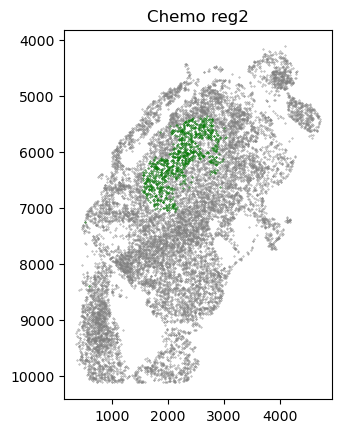

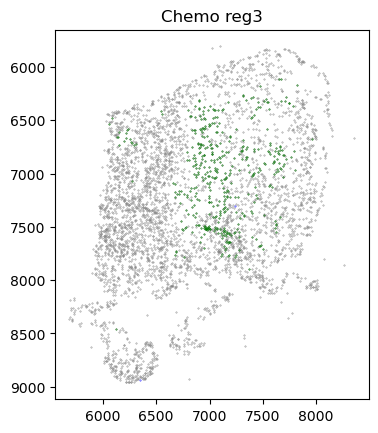

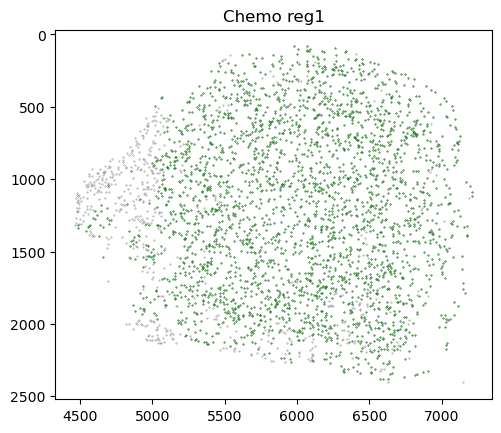

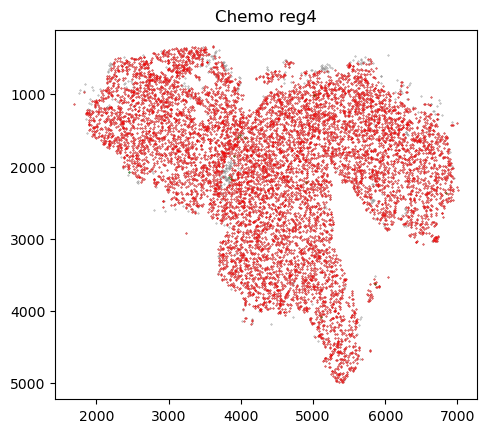

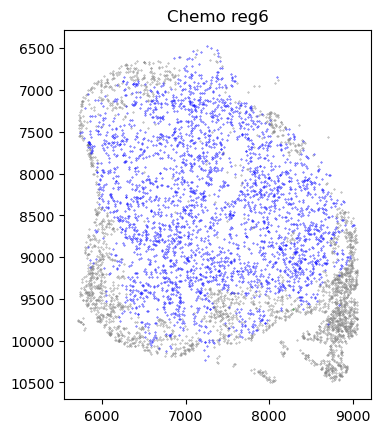

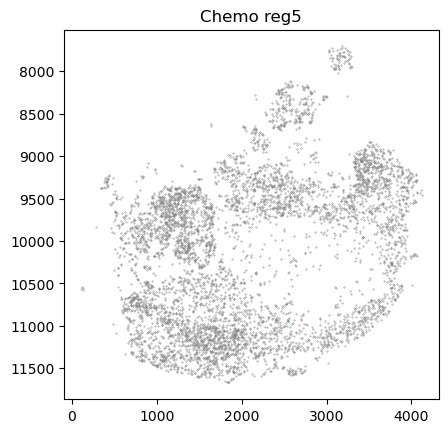

In [26]:
for reg in xen.obs['region'].unique():
    xen_reg = xen[(xen.obs['region']==reg)].obs.sample(frac=.1)
    bg = xen_reg[xen_reg['Epithelial Core']=='Stroma']
    tum = xen_reg[xen_reg['Epithelial Core']=='Intratumoral']
    tumM = xen_reg[xen_reg['Mesenchymal Core']=='Intratumoral']
    tumI = xen_reg[xen_reg['ISG Core']=='Intratumoral']


    plt.scatter(*bg.loc[:,['x','y']].values.T,s=.1,c='grey')
    plt.scatter(*tum.loc[:,['x','y']].values.T,s=.1,c='blue')
    plt.scatter(*tumM.loc[:,['x','y']].values.T,s=.1,c='red')
    plt.scatter(*tumI.loc[:,['x','y']].values.T,s=.1,c='green')
    plt.gca().set_aspect('equal')
    plt.ylim(plt.ylim()[::-1])
    plt.title(reg)
    plt.show()

## 3. Identify cell infiltration and gene expression differences between compartments 

In [27]:
xen.obs.head()

,cell_id,x,y,cell_area,samp,condition,region,Tumor Core,Cell Type,tumor cell leiden,Epithelial Core,ISG Core,Mesenchymal Core
0,aaaahjjl-1,799.092346,6746.838379,191.236726,chemo1,chemo,Chemo reg2,Stroma,unknown,NaN,Stroma,Stroma,Stroma
1,aaaajiam-1,816.627136,6738.786133,88.099847,chemo1,chemo,Chemo reg2,Stroma,unknown,NaN,Stroma,Stroma,Stroma
2,aaaajjfc-1,825.193665,6753.208496,210.608758,chemo1,chemo,Chemo reg2,Stroma,unknown,NaN,Stroma,Stroma,Stroma
3,aaabbjll-1,814.940186,6746.884766,117.270786,chemo1,chemo,Chemo reg2,Stroma,unknown,NaN,Stroma,Stroma,Stroma
4,aaabgicc-1,807.501282,6753.062012,136.733130,chemo1,chemo,Chemo reg2,Stroma,CD8,NaN,Stroma,Stroma,Stroma


#### 3.1 What are gene expression differences between macrophages in different tumor EMT core regions? 

In [28]:
# Normalize Xenium data (Xen is unnormalized)
cluster_genes = list(xen.var_names)
raw_xen = xen[:,cluster_genes].copy() 
norm_xen = sc.pp.normalize_total(raw_xen, copy=True) # Normalizes 

sc.pp.log1p(norm_xen) # Log-transform 

/home/nig060/miniconda3/envs/python3.10/lib/python3.10/site-packages/legacy_api_wrap/__init__.py:88: UserWarning: Some cells have zero counts
  return fn(*args_all, **kw)


In [29]:
# 
mask = sigs_ad.X[:, sigs_ad.var_names == "mono/mac"].flatten() > 0.3
macrophage_subset = norm_xen[mask].copy()

In [30]:
macrophage_subset.shape # 34679 cells 

(34679, 300)

In [31]:
# Cluster the macrophages with all genes first? 
#raw_all_genes should be gene counts
sc.pp.neighbors(macrophage_subset)
sc.tl.leiden(macrophage_subset, resolution=0.3)
sc.tl.umap(macrophage_subset,min_dist=.1)


/home/nig060/miniconda3/envs/python3.10/lib/python3.10/site-packages/scanpy/neighbors/__init__.py:577: UserWarning: You’re trying to run this on 300 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.
  x = _choose_representation(self._adata, use_rep=use_rep, n_pcs=n_pcs)


In [32]:
tumor_genes=['Epcam', 'Cdh1', 'Cdh2', 'Snai2', 'Plekhs1', 'Krt5', 'Col17a1', 'Twist2', 'Cd44', 'Zeb1', 'Zeb2', 'Twist1', 'S100a4', 'Snai1', 'Col6a2', 'EGFP', 'mCherry']

t_signature=['Cd3d', 'Cd3e', 'Cd4', 'Cd8a', 'Cd8b1', 'Trac', 'Cd247', 'Trbc1', 'Foxp3']

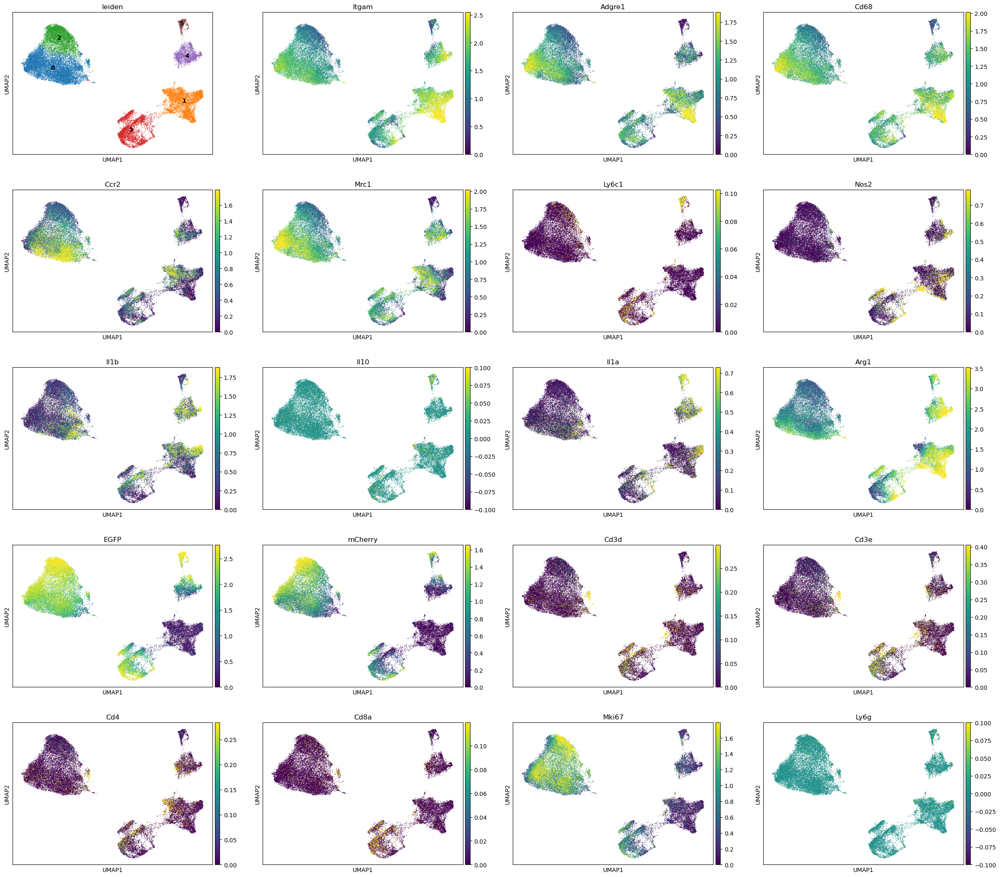

In [33]:
sc.pl.umap(macrophage_subset,color=['leiden',
                'Itgam', 'Adgre1', 'Cd68', 'Ccr2', 'Mrc1', 'Ly6c1', 'Nos2', 'Il1b', 'Il10', 'Il1a', 'Arg1','EGFP', 'mCherry','Cd3d','Cd3e','Cd4','Cd8a','Mki67','Ly6g'],
           legend_loc='on data',
           vmin=0,vmax='p95') # Cluster 6: T cells, Cluster 2 and 5: mostly tumor cells. Clusters 0 and 3 are proliferating myeloid cells

In [34]:
# Remove clusters 2, 5, 6
macrophage = macrophage_subset[macrophage_subset.obs["leiden"].isin(['0','1','3','4'])].copy()
macrophage.shape # 27837 cells 

(27837, 300)

In [35]:
# Remove other things
markers = ["EGFP", "mCherry", "Cd3e"]
expr = macrophage[:, markers].to_df()

mask = (
    (expr["EGFP"] < 2.4) &
    (expr["mCherry"] < 1.3) &
    (expr["Cd3e"] < 0.3)
)

macrophages = macrophage[mask].copy()
macrophages.shape

(21270, 300)

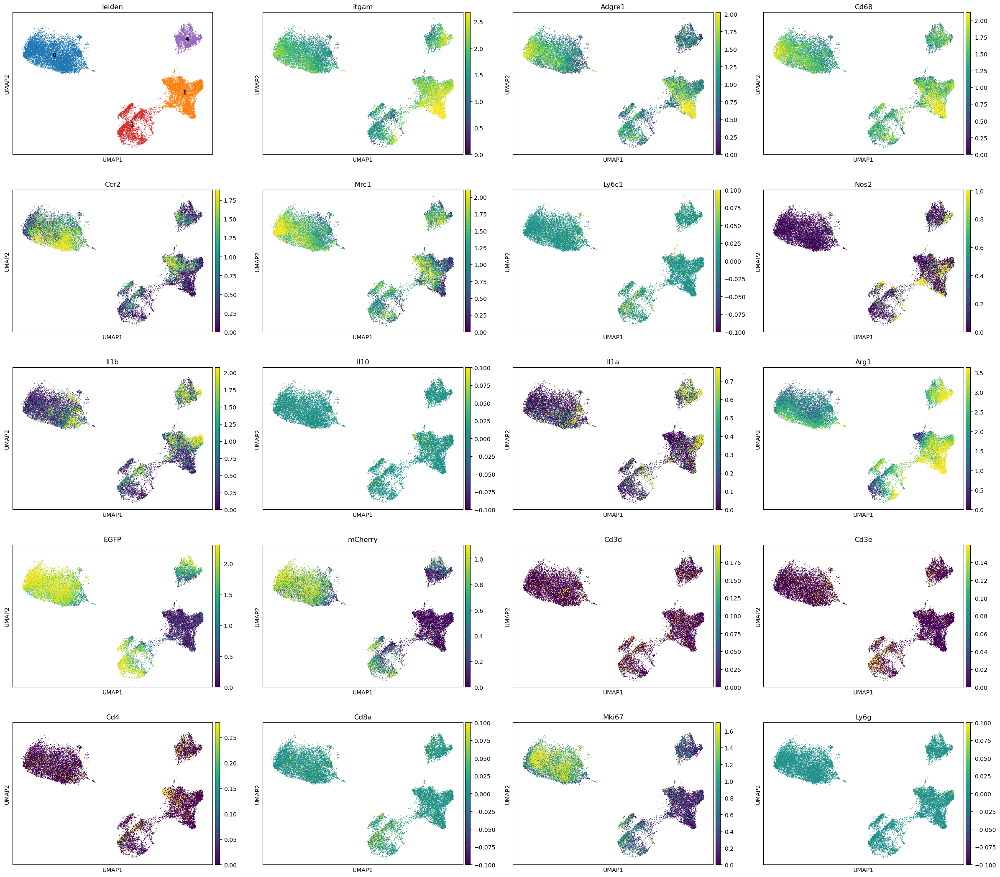

In [36]:
sc.pl.umap(macrophages,color=['leiden',
                'Itgam', 'Adgre1', 'Cd68', 'Ccr2', 'Mrc1', 'Ly6c1', 'Nos2', 'Il1b', 'Il10', 'Il1a', 'Arg1','EGFP', 'mCherry','Cd3d','Cd3e','Cd4','Cd8a','Mki67','Ly6g'],
           legend_loc='on data',
           vmin=0,vmax='p95')

In [37]:
markers = ["Cd68", "Mrc1", "Arg1"]
expr = macrophages[:, markers].to_df()

mask = (
    (expr["Cd68"] > 1.5) |
    (expr["Mrc1"] > 1.5) |
    (expr["Arg1"] > 2.0)
)

macrophages = macrophages[mask].copy()
macrophages.shape # 15935 cells 

(15935, 300)

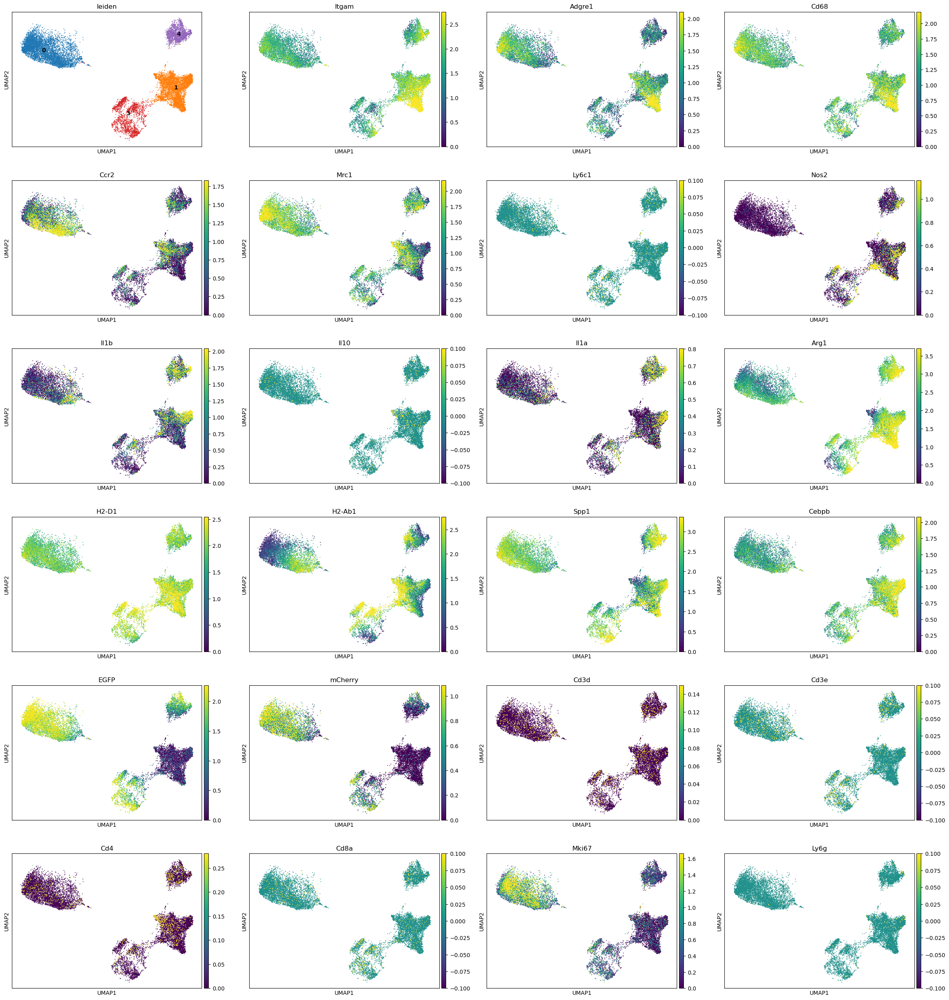

In [38]:
sc.pl.umap(macrophages,color=['leiden',
                'Itgam', 'Adgre1', 'Cd68', 'Ccr2', 'Mrc1', 'Ly6c1', 'Nos2', 'Il1b', 'Il10', 'Il1a', 'Arg1','H2-D1','H2-Ab1','Spp1','Cebpb','EGFP', 'mCherry','Cd3d','Cd3e','Cd4','Cd8a','Mki67','Ly6g'],
           legend_loc='on data',
           vmin=0,vmax='p95')

Here we can see that the rough macrophage_subset contains contamination from tumor cells and T cells, remove those.

In [39]:
macrophages.obs.head()

,cell_id,x,y,cell_area,samp,condition,region,Tumor Core,Cell Type,tumor cell leiden,Epithelial Core,ISG Core,Mesenchymal Core,leiden
2880,adebjipo-1,877.457275,6579.114258,137.094380,chemo1,chemo,Chemo reg2,Stroma,unknown,NaN,Stroma,Stroma,Stroma,1
7293,aidicikg-1,1089.396118,5881.834961,66.695784,chemo1,chemo,Chemo reg2,Stroma,unknown,NaN,Stroma,Stroma,Stroma,1
8866,akafmbcc-1,1530.271973,5228.766113,282.407198,chemo1,chemo,Chemo reg2,Stroma,unknown,NaN,Stroma,Stroma,Stroma,1
10419,alkhpmii-1,2352.824219,4569.458008,50.304064,chemo1,chemo,Chemo reg2,Stroma,unknown,NaN,Stroma,Stroma,Stroma,1
10427,alkipecf-1,2360.953125,4513.810059,97.221410,chemo1,chemo,Chemo reg2,Stroma,unknown,NaN,Stroma,Stroma,Stroma,1


In [40]:
# Compare between Intratumoral vs. Stroma macrophage
sum(macrophages.obs["Tumor Core"] == "Intratumoral") # 7601
sum(macrophages.obs["Tumor Core"] == "Stroma") #8382 cells

8382

leiden           0     1     3     4
Tumor Core                          
Intratumoral  5901    20  1312   320
Stroma         144  5741   642  1855


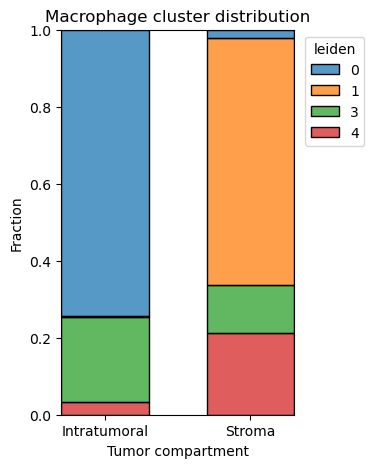

In [41]:
# Distribution of macrophage clusters in tumor cell leiden vs. stroma 
freq_table = pd.crosstab(macrophages.obs["Tumor Core"],macrophages.obs["leiden"])
print(freq_table)

macrophage_df = freq_table.reset_index().melt(id_vars="Tumor Core", var_name="leiden", value_name="Count")

plt.figure(figsize=(3, 5))
ax = sns.histplot(
    data=macrophage.obs, 
    x='Tumor Core', 
    hue='leiden', 
    multiple='fill',
    bins=10, 
    edgecolor='black', shrink=0.6
)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1.02, 1))
plt.title('Macrophage cluster distribution') 
plt.xlabel('Tumor compartment')
plt.ylabel('Fraction')
plt.savefig("./Xenium/Macrophage_Distrubtion.png", dpi=600, bbox_inches="tight")
plt.show()

In [42]:
mac_marker_genes =['Itgam', 'Adgre1', 'Cd68', 'Ccr2', 'Mrc1', 'Nos2', 'Il1b', 'Il1a', 'Arg1','Cebpb','H2-D1','H2-Ab1']

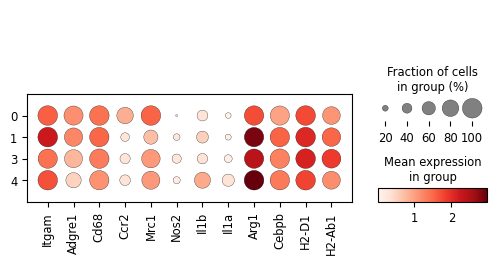

In [43]:
dp = sc.pl.dotplot(
    macrophages, 
    var_names= mac_marker_genes, 
    groupby='leiden',        # Column name in adata.obs for cell types
    cmap='Reds',             # Color map for average expression
    expression_cutoff=0.0,    # Threshold for counting a cell as "expressing"
    colorbar_title='Mean expression\nin group',
    size_title='Fraction of cells\nin group (%)',
    return_fig = True)
dp.savefig('./Xenium/Macrophage_markers.pdf', bbox_inches='tight')

In [71]:
# Differential gene expression between macrophage clusters 0 and 1
sc.tl.rank_genes_groups(
    macrophages,
    groupby="leiden",
    groups=["1"],
    reference="0",
    method="wilcoxon"   # or "t-test", "logreg"
)
de = sc.get.rank_genes_groups_df(macrophages, group=["1"])
de.head(50) # Cluster 0 has higher Mrc1, Socs2, Rela, Junb, EMT genes, proliferation and tumor-related genes

,names,scores,logfoldchanges,pvals,pvals_adj
0,Itgb2,72.146698,1.231335,0.000000e+00,0.000000e+00
1,Itgam,68.031830,1.124134,0.000000e+00,0.000000e+00
2,Arg1,66.377884,1.808314,0.000000e+00,0.000000e+00
3,Cebpb,60.306473,1.127489,0.000000e+00,0.000000e+00
4,Fn1,59.260555,0.807303,0.000000e+00,0.000000e+00
5,C1s1,51.442726,3.924010,0.000000e+00,0.000000e+00
6,Clu,50.163036,2.207752,0.000000e+00,0.000000e+00
7,H2-D1,45.993801,0.529717,0.000000e+00,0.000000e+00
8,Dcn,43.248085,3.443880,0.000000e+00,0.000000e+00
9,Nfkbia,42.539207,0.887803,0.000000e+00,0.000000e+00


In [44]:
# Distribution of macrophage clusters in different Epi, ISG, or Mes cores
# Add macrophage label to the norm_xen.obs metadata 
norm_xen.obs.loc[macrophages.obs_names,'Macrophage leiden'] = macrophages.obs['leiden']
norm_xen.obs.head()

,cell_id,x,y,cell_area,samp,condition,region,Tumor Core,Cell Type,tumor cell leiden,Epithelial Core,ISG Core,Mesenchymal Core,Macrophage leiden
0,aaaahjjl-1,799.092346,6746.838379,191.236726,chemo1,chemo,Chemo reg2,Stroma,unknown,NaN,Stroma,Stroma,Stroma,NaN
1,aaaajiam-1,816.627136,6738.786133,88.099847,chemo1,chemo,Chemo reg2,Stroma,unknown,NaN,Stroma,Stroma,Stroma,NaN
2,aaaajjfc-1,825.193665,6753.208496,210.608758,chemo1,chemo,Chemo reg2,Stroma,unknown,NaN,Stroma,Stroma,Stroma,NaN
3,aaabbjll-1,814.940186,6746.884766,117.270786,chemo1,chemo,Chemo reg2,Stroma,unknown,NaN,Stroma,Stroma,Stroma,NaN
4,aaabgicc-1,807.501282,6753.062012,136.733130,chemo1,chemo,Chemo reg2,Stroma,CD8,NaN,Stroma,Stroma,Stroma,NaN


In [60]:
norm_xen.obs['Macrophage leiden'] = norm_xen.obs['Macrophage leiden'].astype('object').fillna('NotMac')
freq_table = pd.crosstab(norm_xen.obs["Tumor Core"],norm_xen.obs["Macrophage leiden"])
# For Tumor Score == Stroma and Epi Core == Intratumoral... Get macrophage infiltration as % of all cells 
epi = pd.crosstab(norm_xen.obs["Epithelial Core"],norm_xen.obs["Macrophage leiden"]).loc["Intratumoral"]
isg = pd.crosstab(norm_xen.obs["ISG Core"],norm_xen.obs["Macrophage leiden"]).loc["Intratumoral"]
mes = pd.crosstab(norm_xen.obs["Mesenchymal Core"],norm_xen.obs["Macrophage leiden"]).loc["Intratumoral"]
new_rows = pd.DataFrame(
    [
        epi,
        isg,
        mes,
    ],
    columns=freq_table.columns,
    index=["Epithelial", "ISG", "Mesenchymal"]
)

df = pd.concat([freq_table, new_rows])
df
# Plot 
df_sub = df.iloc[1:5,:5]

In [57]:
mes

Macrophage leiden
0          5878
1             5
3            14
4             4
NotMac    83002
Name: Intratumoral, dtype: int64

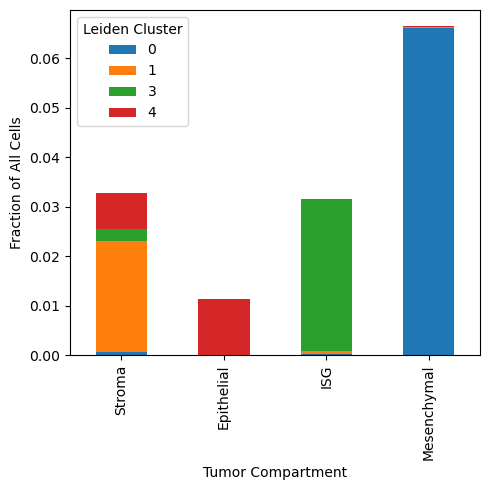

In [61]:
# Plot stacked barplot 
prop_table = df_sub.div(
    df_sub.sum(axis=1),
    axis=0
)
prop_table = prop_table.iloc[:,:4]

prop_table.plot(
    kind="bar",
    stacked=True,
    figsize=(5, 5)
)

plt.xlabel("Tumor Compartment")
plt.ylabel("Fraction of All Cells")
plt.legend(title="Leiden Cluster")
plt.savefig("./Xenium/Macrophage_Normalized.png", dpi=600, bbox_inches="tight")
plt.tight_layout()
plt.show()

### 4. Macrophage gene expression correlated with tumor cell infiltration

In [54]:
# Plot gene expression levels based on how close the nearest 3 tumor cells are

# Get 3 nearest neighbors

# Calculate non-tumor cell distance from nearest 3 tumor cells

# Binning for distance

# Marker expression heatmap 
from sklearn.neighbors import NearestNeighbors
neighbors = 3
tum = norm_xen[norm_xen.obs['Cell Type']=='Tumor cell']
for reg in tqdm(xen.obs['region'].unique()): # Each slide is one region
    xen_reg = norm_xen[norm_xen.obs['region']==reg].obs # Get that slide
    tum_reg = tum[tum.obs['region']==reg].obs
    non_tum = xen_reg.drop(tum_reg.index,axis=0) # Remove tumor cells from all cells in Slide
    if len(tum_reg) < 3: # If fewer than 3 tumor cells in Slide
        norm_xen.obs.loc[non_tum.index,'Tumor Distance']= np.inf 
        continue
    non_pts = non_tum.loc[:,['x','y']].values
    tum_pts = tum_reg.loc[:,['x','y']].values
    tree = NearestNeighbors(n_neighbors=neighbors)
    tree.fit(tum_pts) # Unsupervised for nearest neighbor searches
    distances, indices = tree.kneighbors(non_pts)
    # Get average neighbor_distances
    avg_distances = np.mean(distances,axis=1)
    print(avg_distances.shape)
    norm_xen.obs.loc[non_tum.index,'Tumor Distance'] = avg_distances

  0%|          | 0/6 [00:00<?, ?it/s]

(127094,)
(40956,)
(18558,)
(21483,)
(31274,)
(59959,)


In [55]:
# Subset macrophages again
norm_xen.obs.head()

,cell_id,x,y,cell_area,samp,condition,region,Tumor Core,Cell Type,tumor cell leiden,Epithelial Core,ISG Core,Mesenchymal Core,Macrophage leiden,Tumor Distance
0,aaaahjjl-1,799.092346,6746.838379,191.236726,chemo1,chemo,Chemo reg2,Stroma,unknown,NaN,Stroma,Stroma,Stroma,NaN,512.944394
1,aaaajiam-1,816.627136,6738.786133,88.099847,chemo1,chemo,Chemo reg2,Stroma,unknown,NaN,Stroma,Stroma,Stroma,NaN,525.330198
2,aaaajjfc-1,825.193665,6753.208496,210.608758,chemo1,chemo,Chemo reg2,Stroma,unknown,NaN,Stroma,Stroma,Stroma,NaN,515.034782
3,aaabbjll-1,814.940186,6746.884766,117.270786,chemo1,chemo,Chemo reg2,Stroma,unknown,NaN,Stroma,Stroma,Stroma,NaN,517.506901
4,aaabgicc-1,807.501282,6753.062012,136.733130,chemo1,chemo,Chemo reg2,Stroma,CD8,NaN,Stroma,Stroma,Stroma,NaN,509.708922


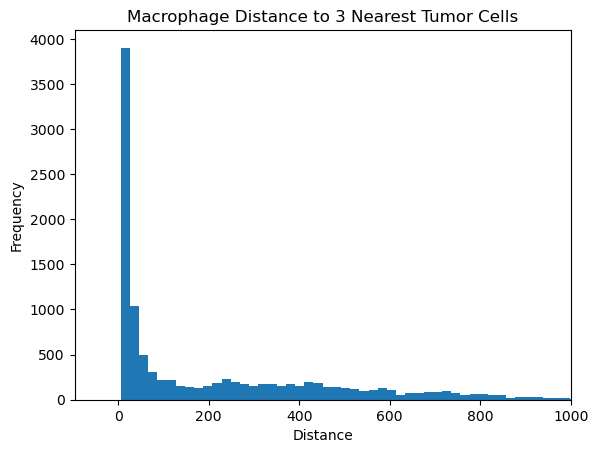

In [62]:
# Plot distribution of distances to tumors
macrophages = norm_xen[norm_xen.obs["Macrophage leiden"].notna()].copy()
# Plot distance to nearest 3 tumor cells
plt.hist(macrophages.obs["Tumor Distance"], bins=100,)
plt.title("Macrophage Distance to 3 Nearest Tumor Cells")
plt.xlabel("Distance")
plt.ylabel("Frequency")
plt.xlim(xmax=1000)
plt.savefig("./Xenium/Macrophage_Tumor_Distance.png", dpi=600, bbox_inches="tight")
plt.show()

[   5.38016863   14.3578248    35.49519431  212.11708649  475.75887604
 2033.8810853 ]


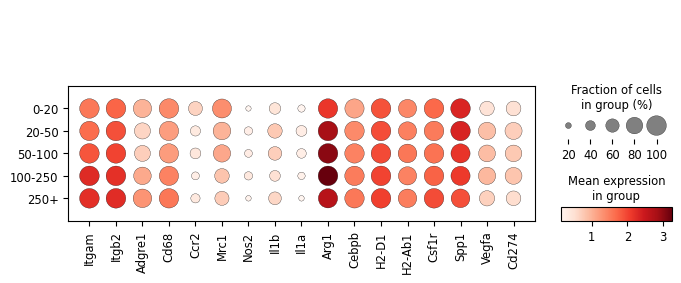

In [66]:
# Calculate percentile of distances and binning
macrophages.obs["tumor_distance_bin"] = pd.qcut(
    macrophages.obs["Tumor Distance"],
    q=5,
    labels=["Q1", "Q2", "Q3", "Q4", "Q5"]
)
macrophages.obs["tumor_distance_bin2"] = pd.cut(
    macrophages.obs["Tumor Distance"],
    bins=[0,20,50,100,250,np.inf],
    labels=["0-20", "20-50", "50-100", "100-250", "250+"]
)
# Get the actual bins
bins = pd.qcut(
    macrophages.obs["Tumor Distance"],
    q=5,
    retbins=True
)
print(bins[1])
# Plot marker expression bubbleplot
mac_marker_genes =['Itgam','Itgb2','Adgre1', 'Cd68', 'Ccr2', 'Mrc1', 
                   'Nos2', 'Il1b', 'Il1a', 'Arg1','Cebpb','H2-D1','H2-Ab1','Csf1r','Spp1','Vegfa','Cd274']
dp = sc.pl.dotplot(
    macrophages, 
    var_names= mac_marker_genes, 
    groupby='tumor_distance_bin2',        # Column name in adata.obs for cell types
    cmap='Reds',             # Color map for average expression
    expression_cutoff=0.0,    # Threshold for counting a cell as "expressing"
    colorbar_title='Mean expression\nin group',
    size_title='Fraction of cells\nin group (%)',
    return_fig = True)
dp.savefig('./Xenium/Macrophage_markers_by_tumor_distance.pdf', bbox_inches='tight')

#### 4.2 Macrophage gene expression correlated with % tumor cells in 20 closest neighbors, using Lasso regression

#### 4.3 Find genes enriched near a macrophage cell state

In [ ]:
# Are Mac enriched near Cebpb-Hi tumor cells


In [74]:
# Get ratio of Intratumoral/Stroma in each macrophage cluster
# Get DEGs between Macrophage Leiden clusters (0, 1, 3, 4)

In [44]:
# Are there differences in immune/stromal composition between the tumor compartments?
macrophage_subset.obs.head()

,cell_id,x,y,cell_area,samp,condition,region,Tumor Core,Cell Type,tumor cell leiden,Epithelial Core,ISG Core,Mesenchymal Core


In [76]:
norm_xen.obs['Cell Type'].value_counts()

Cell Type
unknown               251270
Tumor cell            118128
Endothelial cell       23091
Non-regulatory CD4     11058
CD8                     8422
mat.DC                  2490
Treg                    1381
pDC                      822
CD8/CD4                  352
cDC1                     241
Lymphatic cell           197
Name: count, dtype: int64

In [63]:
xen.obs_names[1:5]

Index(['1', '2', '3', '4'], dtype='object')

## 5. Xenium analysis from scratch

In [19]:
xen =sc.read_h5ad('./Mouse_TME_CODEX/20260623__194743__graham_take2/usefuldata/2026_0710_chemoxeniumanndata')

Text(0, 0.5, 'Number of cells')

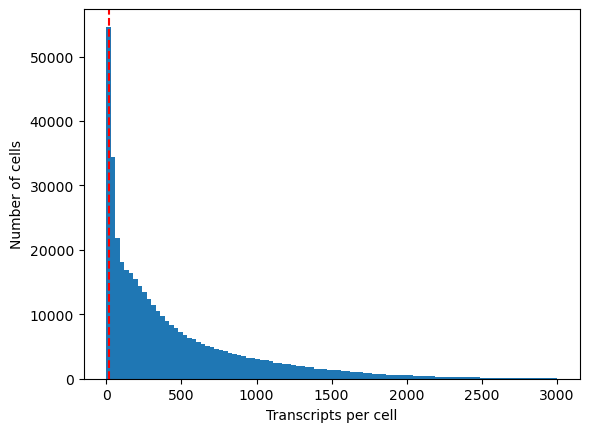

In [20]:
# Check and filter
sc.pp.calculate_qc_metrics(xen, percent_top=None, inplace=True)
fig = plt.hist(xen.obs["total_counts"], range=(0, 3000), bins=100)
plt.axvline(x=20, color="r", linestyle="--")  # You can customize color and linestyle

plt.xlabel("Transcripts per cell")
plt.ylabel("Number of cells")

In [21]:
# Filtering 
# Based on the histogram plot, here we choose 20 transcript counts as lower cutoff
thres = np.quantile(xen.obs["total_counts"], 0.99)
sc.pp.filter_cells(xen, min_counts=20)
sc.pp.filter_cells(xen, max_counts=thres)

In [22]:
# Save raw counts in a layer just in case
xen.layers["counts"] = xen.X.copy()

# Standard normalization & log transform
sc.pp.normalize_total(xen, target_sum=1e4)
sc.pp.log1p(xen)
xen.layers["lognorm"] = xen.X.copy()

In [23]:
# Get max value
sc.pp.scale(xen, zero_center=False, max_value=10)
# PCA for dimension reduction further by UMAP for downstream analysis
sc.pp.pca(xen, n_comps=30)

In [24]:
import harmonypy as hp

# 1. Grab your PCA coordinates
pca_coords = xen.obsm["X_pca"].astype("float64")

# 2. Run harmonypy directly
# (This is exactly what Scanpy does under the hood)
harmony_out = hp.run_harmony(pca_coords, xen.obs, "samp")

# 3. Manually map the correct coordinate array to your object
xen.obsm["X_pca_harmony"] = harmony_out.result()

2026-09-14 15:22:03,651 - harmonypy - INFO - Running Harmony
2026-09-14 15:22:03,654 - harmonypy - INFO -   Parameters:
2026-09-14 15:22:03,655 - harmonypy - INFO -     max_iter_harmony: 10
2026-09-14 15:22:03,657 - harmonypy - INFO -     max_iter_kmeans: 4
2026-09-14 15:22:03,659 - harmonypy - INFO -     epsilon_cluster: 0.001
2026-09-14 15:22:03,660 - harmonypy - INFO -     epsilon_harmony: 0.01
2026-09-14 15:22:03,662 - harmonypy - INFO -     nclust: 100
2026-09-14 15:22:03,663 - harmonypy - INFO -     block_size: 0.05
2026-09-14 15:22:03,665 - harmonypy - INFO -     lamb: dynamic (alpha=0.2)
2026-09-14 15:22:03,667 - harmonypy - INFO -     theta: [2. 2.]
2026-09-14 15:22:03,669 - harmonypy - INFO -     sigma: [0.1 0.1 0.1 0.1 0.1]...
2026-09-14 15:22:03,671 - harmonypy - INFO -     verbose: True
2026-09-14 15:22:03,673 - harmonypy - INFO -     random_state: 0
2026-09-14 15:22:03,674 - harmonypy - INFO -   Data: 30 PCs × 377012 cells
2026-09-14 15:22:03,676 - harmonypy - INFO -   Ba

In [26]:
# Find neighbors
sc.pp.neighbors(xen,use_rep="X_pca_harmony")
# clustering with leiden. We use igraph here as it scales better. The resolution is a hyper-parameter. A higher resolution will output more clusters.
sc.tl.leiden(xen, flavor="igraph", n_iterations=-1, resolution=0.5)
# Run UMAP
sc.tl.umap(xen)

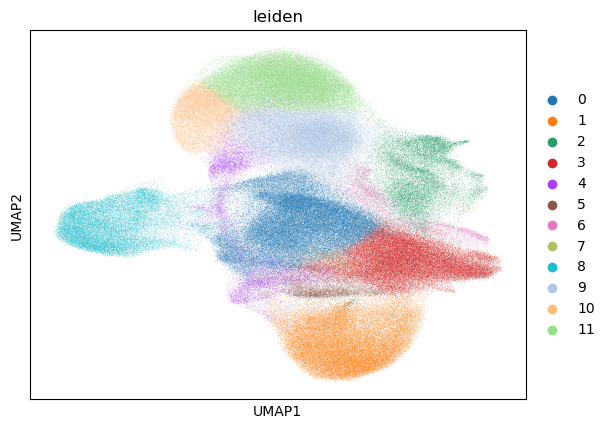

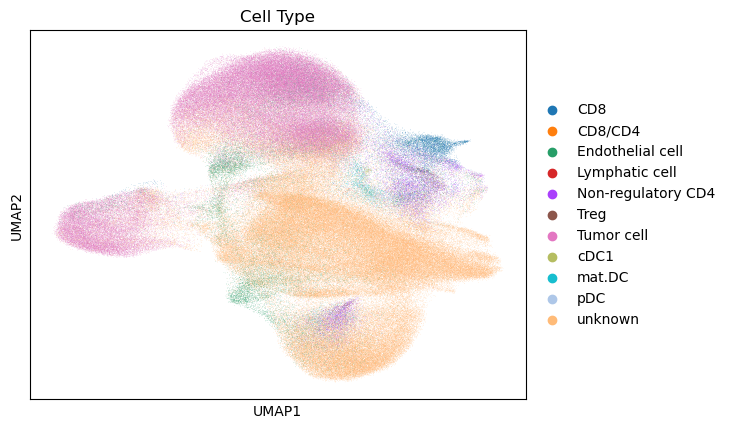

In [27]:
# Plot UMAP
sc.pl.umap(xen, color="leiden",show=False)
plt.savefig("./Xenium/UMAP_Leiden.png", bbox_inches="tight",dpi=600)
sc.pl.umap(xen, color=['Cell Type'],
#            vmin=.5,vmax=2
           vmin = 'p05',vmax='p99', show=False)
plt.savefig("./Xenium/UMAP_Cell_Type.png", bbox_inches="tight",dpi=600)

In [28]:
# Check Leiden markers
sc.tl.rank_genes_groups(xen, groupby="leiden", layer="lognorm", pts=True)

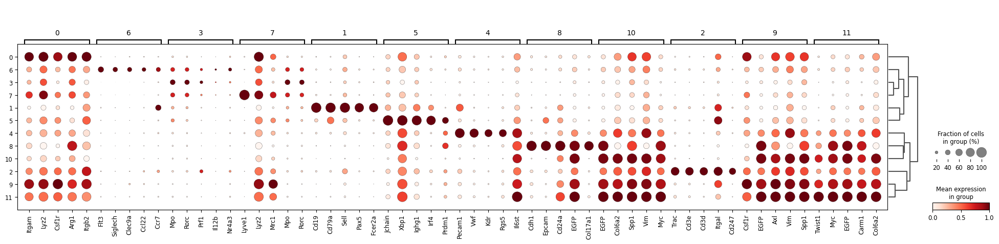

In [30]:
sc.pl.rank_genes_groups_dotplot(xen, n_genes=5, show=False, standard_scale='var')
plt.savefig("./Xenium/Marker_dotplot.png", bbox_inches="tight",dpi=600)

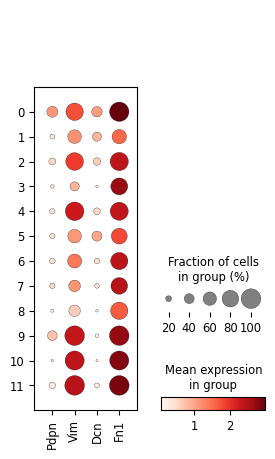

In [45]:
# Specifically plot fibroblast genes
sc.pl.dotplot(
    xen, 
    var_names= ['Pdpn','Vim','Dcn','Fn1'], 
    groupby='leiden',        # Column name in adata.obs for cell types
    cmap='Reds',             # Color map for average expression
    expression_cutoff=0.0,    # Threshold for counting a cell as "expressing"
    colorbar_title='Mean expression\nin group',
    size_title='Fraction of cells\nin group (%)',show=False)
plt.savefig("./Xenium/Stromal Markers.png", bbox_inches="tight",dpi=600)

In [35]:
# Add spatial entry from coordinates in cell metadata
x_coords = xen.obs["x"].values
y_coords = xen.obs["y"].values

# Stack them horizontally into a single array of shape (377012, 2)
xen.obsm["spatial"] = np.column_stack((x_coords, y_coords))

/tmp/ipykernel_113812/3179280638.py:11: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/tmp/ipykernel_113812/3179280638.py:11: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/tmp/ipykernel_113812/3179280638.py:11: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/tmp/ipykernel_113812/3179280638.py:11: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/tmp/ipykernel_113812/3179280638.py:11: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/tmp/ipykernel_113812/3179280638.py:11: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


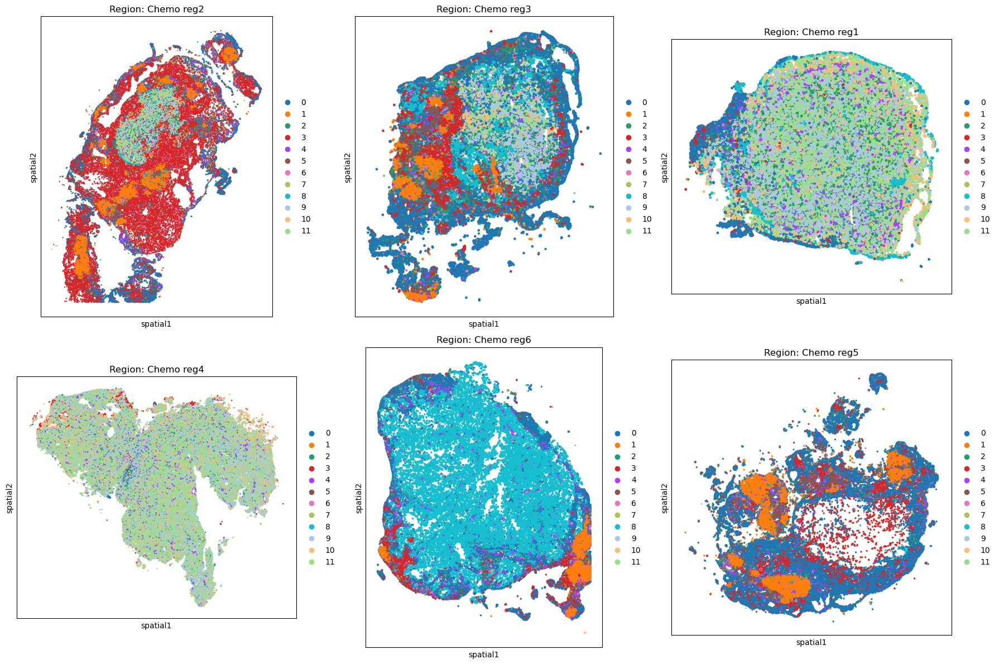

In [37]:
regs = xen.obs['region'].unique()
# Create a 2x3 grid of subplots
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for i, reg_id in enumerate(regs):
    # Subset data for just this region
    subset = xen[xen.obs["region"] == reg_id].copy()
    
    # Plot on its own dedicated subplot axis
    sc.pl.spatial(
        subset, 
        color="leiden", 
        spot_size=30, 
        img_key=None, 
        ax=axes[i], 
        show=False,
        title=f"Region: {reg_id}"
    )

plt.tight_layout()
plt.savefig("./Xenium/Spatial Visulization Clusters.png", bbox_inches="tight",dpi=600)
plt.show()

In [34]:
xen.obs.head()

,cell_id,x,y,cell_area,samp,condition,region,Tumor Core,Cell Type,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,n_counts,leiden
0,aaaahjjl-1,799.092346,6746.838379,191.236726,chemo1,chemo,Chemo reg2,Stroma,unknown,68,4.234107,181.0,5.204007,181.0,0
1,aaaajiam-1,816.627136,6738.786133,88.099847,chemo1,chemo,Chemo reg2,Stroma,unknown,43,3.784190,88.0,4.488636,88.0,0
2,aaaajjfc-1,825.193665,6753.208496,210.608758,chemo1,chemo,Chemo reg2,Stroma,unknown,68,4.234107,256.0,5.549076,256.0,0
3,aaabbjll-1,814.940186,6746.884766,117.270786,chemo1,chemo,Chemo reg2,Stroma,unknown,58,4.077537,124.0,4.828314,124.0,1
4,aaabgicc-1,807.501282,6753.062012,136.733130,chemo1,chemo,Chemo reg2,Stroma,CD8,76,4.343805,197.0,5.288267,197.0,2


In [38]:
xen.obs.head()

,cell_id,x,y,cell_area,samp,condition,region,Tumor Core,Cell Type,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,n_counts,leiden
0,aaaahjjl-1,799.092346,6746.838379,191.236726,chemo1,chemo,Chemo reg2,Stroma,unknown,68,4.234107,181.0,5.204007,181.0,0
1,aaaajiam-1,816.627136,6738.786133,88.099847,chemo1,chemo,Chemo reg2,Stroma,unknown,43,3.784190,88.0,4.488636,88.0,0
2,aaaajjfc-1,825.193665,6753.208496,210.608758,chemo1,chemo,Chemo reg2,Stroma,unknown,68,4.234107,256.0,5.549076,256.0,0
3,aaabbjll-1,814.940186,6746.884766,117.270786,chemo1,chemo,Chemo reg2,Stroma,unknown,58,4.077537,124.0,4.828314,124.0,1
4,aaabgicc-1,807.501282,6753.062012,136.733130,chemo1,chemo,Chemo reg2,Stroma,CD8,76,4.343805,197.0,5.288267,197.0,2


In [39]:
xen.obs["leiden"].value_counts()

leiden
0     69480
11    58602
3     51203
1     49769
9     45143
8     29474
2     24368
10    16622
4     15303
5      8132
6      7142
7      1774
Name: count, dtype: int64

Cluster annotation: 
Clusters 8, 10, 11: Tumor cells (8: Epi, 10, 11: Mes)
Cluster 0, 9: Macrophages (some stroma contamination)
Cluster 1: B cells
Cluster 2: T cells
Cluster 3: Stroma
Cluster 4: Endothelial cells
Cluster 5: Plasma cells
Cluster 6: DCs 
Cluster 7: lymphatic endothelial cells 

In [40]:
# Label cell types
cluster_annotation = {
    '0': 'Macrophages',
    '1': 'B cells',
    '2': 'T cells',
    '3': 'Stroma',
    '4': 'Endothelial cells',
    '5': 'Plasma cells',
    '6': 'DCs',
    '7': 'Lymphatic endothelial cells',
    '8': 'Tumor cells',
    '9': 'Macrophages',
    '10': 'Tumor cells',
    '11': 'Tumor cells'
}
xen.obs['cell_type'] = xen.obs['leiden'].map(cluster_annotation)
xen.obs["cell_type"].value_counts()

cell_type
Macrophages                    114623
Tumor cells                    104698
Stroma                          51203
B cells                         49769
T cells                         24368
Endothelial cells               15303
Plasma cells                     8132
DCs                              7142
Lymphatic endothelial cells      1774
Name: count, dtype: int64

In [46]:
# Save processed object 
xen.write_h5ad("./Xenium/Graham_Chemo_Take2.h5ad")

### 5.2 Subclustering of Tumor cells and Macrophages,

In [2]:
xen = sc.read_h5ad("./Xenium/Graham_Chemo_Take2.h5ad")

In [3]:
xen.obs.head()

,cell_id,x,y,cell_area,samp,condition,region,Tumor Core,Cell Type,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,n_counts,leiden,cell_type
0,aaaahjjl-1,799.092346,6746.838379,191.236726,chemo1,chemo,Chemo reg2,Stroma,unknown,68,4.234107,181.0,5.204007,181.0,0,Macrophages
1,aaaajiam-1,816.627136,6738.786133,88.099847,chemo1,chemo,Chemo reg2,Stroma,unknown,43,3.784190,88.0,4.488636,88.0,0,Macrophages
2,aaaajjfc-1,825.193665,6753.208496,210.608758,chemo1,chemo,Chemo reg2,Stroma,unknown,68,4.234107,256.0,5.549076,256.0,0,Macrophages
3,aaabbjll-1,814.940186,6746.884766,117.270786,chemo1,chemo,Chemo reg2,Stroma,unknown,58,4.077537,124.0,4.828314,124.0,1,B cells
4,aaabgicc-1,807.501282,6753.062012,136.733130,chemo1,chemo,Chemo reg2,Stroma,CD8,76,4.343805,197.0,5.288267,197.0,2,T cells


In [4]:
# Re-cluster the Tumor cells into subsets
tumor_subset = xen[xen.obs['cell_type'] == 'Tumor cells'].copy()
print(tumor_subset.shape)

# 5. Re-run Neighbors, UMAP, and Clustering
sc.pp.neighbors(tumor_subset, use_rep="X_pca_harmony")  # Adjust n_pcs as needed
sc.tl.umap(tumor_subset, min_dist=0.1)
sc.tl.leiden(tumor_subset, resolution=0.2, key_added='Tumor Subclusters')

(104698, 300)


/tmp/ipykernel_2121664/4242873708.py:8: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(tumor_subset, resolution=0.2, key_added='Tumor Subclusters')


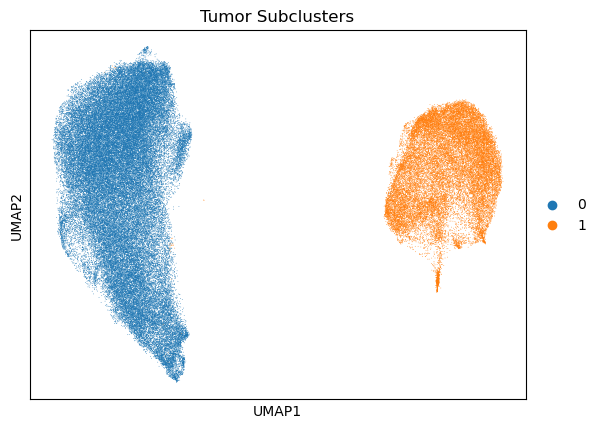

In [5]:
# 6. Plot the new subclusters
sc.pl.umap(tumor_subset, color=['Tumor Subclusters'],show=False)
plt.savefig("./Xenium/Tumor Subclusters UMAP.png", bbox_inches="tight",dpi=600)

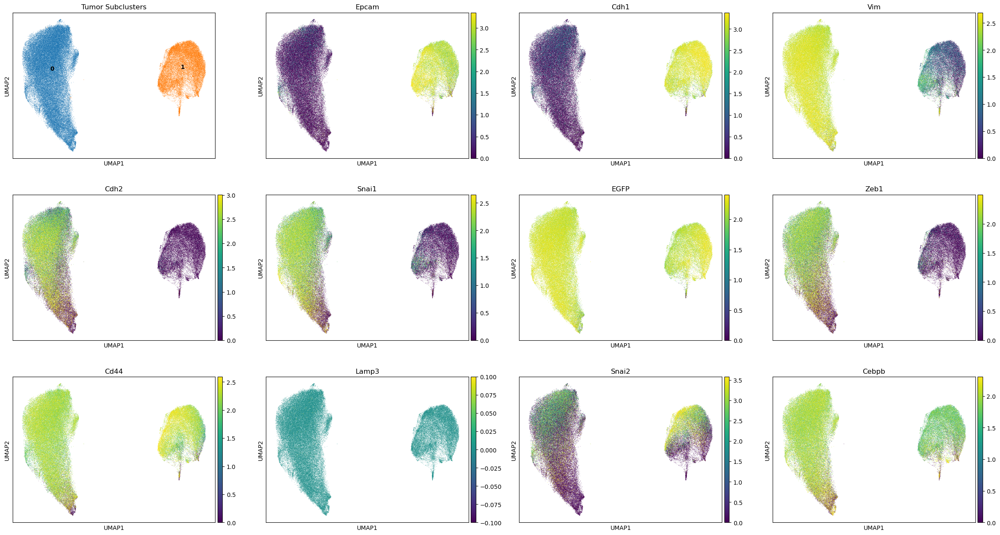

In [9]:
sc.pl.umap(tumor_subset,color=['Tumor Subclusters',
                'Epcam','Cdh1','Vim','Cdh2','Snai1','EGFP','Zeb1','Cd44','Lamp3','Snai2','Cebpb'],
           legend_loc='on data',
           vmin=0,vmax='p95',show=False) # Clearly 2 clusters: Epi, Mes
plt.savefig("./Xenium/Tumor Markers UMAP.png", bbox_inches="tight",dpi=600)

In [10]:
# Add tumor cell labels to whole dataset metadata
xen.obs.loc[tumor_subset.obs_names,'Tumor leiden'] = tumor_subset.obs['Tumor Subclusters']

In [11]:
# Subclustering of just the Macrophages
macrophage_subset = xen[xen.obs['cell_type'] == 'Macrophages'].copy()
print(macrophage_subset.shape)

# 5. Re-run Neighbors, UMAP, and Clustering
sc.pp.neighbors(macrophage_subset, use_rep="X_pca_harmony")
sc.tl.umap(macrophage_subset, min_dist=0.1)
sc.tl.leiden(macrophage_subset, resolution=0.4)

(114623, 300)


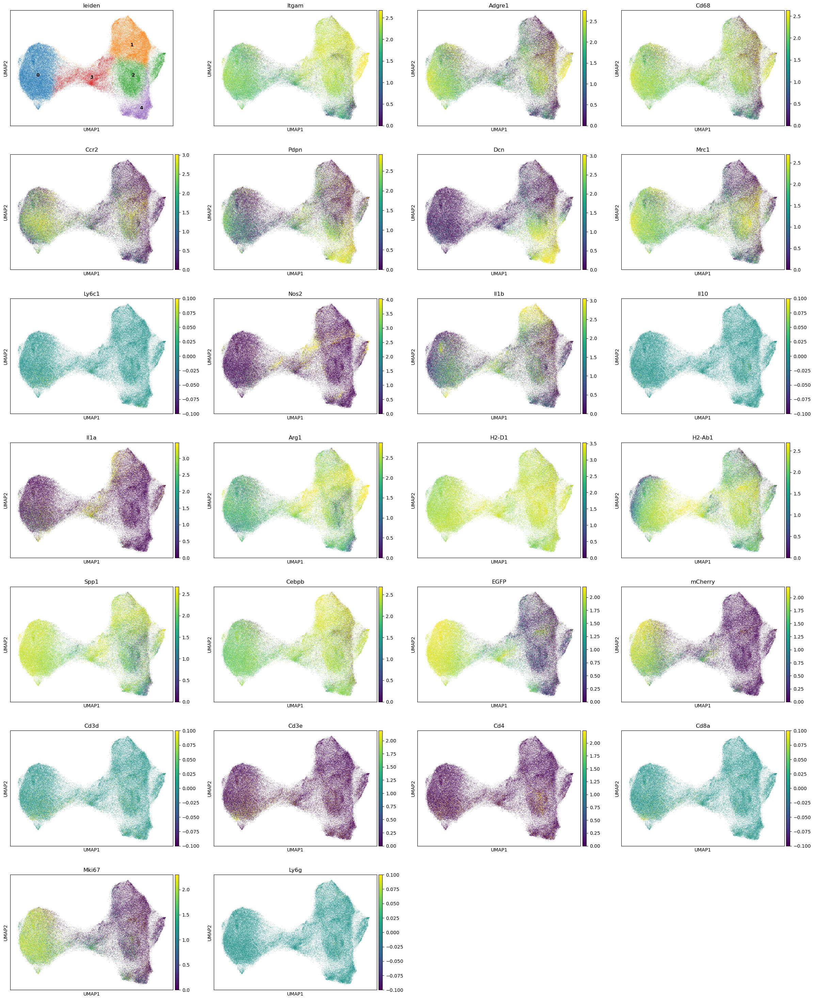

In [13]:
# Look at macrophage markers and markers for potential contaminating clusters
sc.pl.umap(macrophage_subset,color=['leiden',
                'Itgam', 'Adgre1', 'Cd68', 'Ccr2', 'Pdpn','Dcn','Mrc1', 'Ly6c1', 'Nos2', 'Il1b', 'Il10', 'Il1a', 'Arg1','H2-D1','H2-Ab1','Spp1','Cebpb','EGFP', 'mCherry','Cd3d','Cd3e','Cd4','Cd8a','Mki67','Ly6g'],
           legend_loc='on data',
           vmin=0,vmax='p95', show=False)
plt.savefig("./Xenium/Macrophage Markers UMAP.png", bbox_inches="tight",dpi=600)

In [17]:
# Cluster 4 is Stroma, Cluster 0 might be tumor-infiltrating macrophages
# Label cluster 4 as stroma, remove cluster 4, and re-cluster the macrophages
cluster_annotation = {
    '0': 'Macrophages',
    '1': 'Macrophages',
    '2': 'Macrophages',
    '3': 'Macrophages',
    '4': 'Stroma'
}
macrophage_subset.obs['cell_type'] = macrophage_subset.obs['leiden'].map(cluster_annotation)
macrophage_subset.obs.head()

,cell_id,x,y,cell_area,samp,condition,region,Tumor Core,Cell Type,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,n_counts,leiden,cell_type,Tumor leiden
0,aaaahjjl-1,799.092346,6746.838379,191.236726,chemo1,chemo,Chemo reg2,Stroma,unknown,68,4.234107,181.0,5.204007,181.0,4,Stroma,NaN
1,aaaajiam-1,816.627136,6738.786133,88.099847,chemo1,chemo,Chemo reg2,Stroma,unknown,43,3.784190,88.0,4.488636,88.0,2,Macrophages,NaN
2,aaaajjfc-1,825.193665,6753.208496,210.608758,chemo1,chemo,Chemo reg2,Stroma,unknown,68,4.234107,256.0,5.549076,256.0,2,Macrophages,NaN
5,aaabicdb-1,844.782227,6744.733398,107.200941,chemo1,chemo,Chemo reg2,Stroma,unknown,48,3.891820,130.0,4.875197,130.0,1,Macrophages,NaN
7,aaabofal-1,849.680542,6734.991211,115.374223,chemo1,chemo,Chemo reg2,Stroma,unknown,52,3.970292,122.0,4.812184,122.0,1,Macrophages,NaN


In [18]:
# Set Cluster 4 to Stroma in xen too 
xen.obs.loc[macrophage_subset.obs_names,'cell_type'] = macrophage_subset.obs['cell_type']

In [19]:
xen.obs.head()

,cell_id,x,y,cell_area,samp,condition,region,Tumor Core,Cell Type,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,n_counts,leiden,cell_type,Tumor leiden
0,aaaahjjl-1,799.092346,6746.838379,191.236726,chemo1,chemo,Chemo reg2,Stroma,unknown,68,4.234107,181.0,5.204007,181.0,0,Stroma,NaN
1,aaaajiam-1,816.627136,6738.786133,88.099847,chemo1,chemo,Chemo reg2,Stroma,unknown,43,3.784190,88.0,4.488636,88.0,0,Macrophages,NaN
2,aaaajjfc-1,825.193665,6753.208496,210.608758,chemo1,chemo,Chemo reg2,Stroma,unknown,68,4.234107,256.0,5.549076,256.0,0,Macrophages,NaN
3,aaabbjll-1,814.940186,6746.884766,117.270786,chemo1,chemo,Chemo reg2,Stroma,unknown,58,4.077537,124.0,4.828314,124.0,1,B cells,NaN
4,aaabgicc-1,807.501282,6753.062012,136.733130,chemo1,chemo,Chemo reg2,Stroma,CD8,76,4.343805,197.0,5.288267,197.0,2,T cells,NaN


In [20]:
# Now sub-cluster the macrophages with tumor cells
tumor_macrophage = xen[xen.obs['cell_type'].isin(['Tumor cells','Macrophages'])].copy()
tumor_macrophage.shape

(207401, 300)

In [21]:
# 5. Re-run Neighbors, UMAP, and Clustering
sc.pp.neighbors(tumor_macrophage, use_rep="X_pca_harmony")  # Adjust n_pcs as needed
sc.tl.umap(tumor_macrophage, min_dist=0.1)
sc.tl.leiden(tumor_macrophage, resolution=0.4)

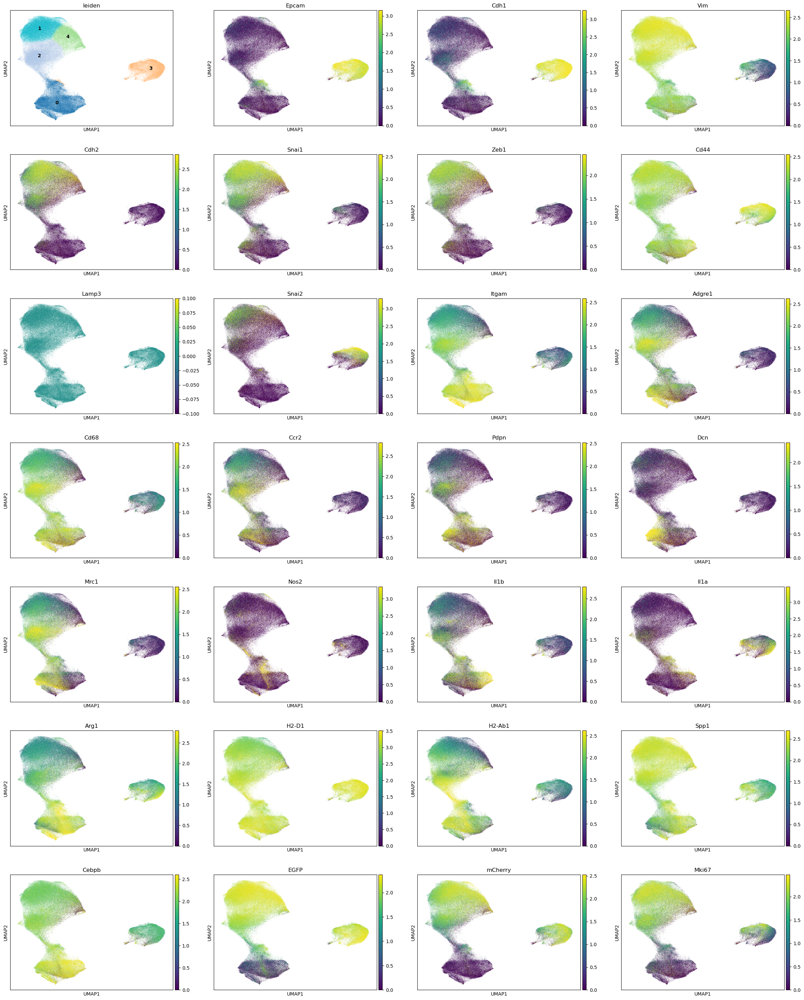

In [23]:
# Look at macrophage markers and markers for potential contaminating clusters
sc.pl.umap(tumor_macrophage,color=['leiden','Epcam','Cdh1','Vim','Cdh2','Snai1','Zeb1','Cd44','Lamp3','Snai2',
                'Itgam', 'Adgre1', 'Cd68', 'Ccr2', 'Pdpn','Dcn','Mrc1', 'Nos2', 'Il1b', 'Il1a', 'Arg1','H2-D1','H2-Ab1','Spp1','Cebpb','EGFP', 'mCherry','Mki67'],
           legend_loc='on data',
           vmin=0,vmax='p95', show=False)
plt.savefig("./Xenium/Tumor Macrophage Markers UMAP.png", bbox_inches="tight",dpi=600)

In [28]:
tumor_macrophage.obs[["cell_type","leiden"]].value_counts()

cell_type    leiden
Macrophages  0         57332
Tumor cells  1         50600
Macrophages  2         42850
Tumor cells  3         29479
             4         23651
Macrophages  4          1617
Tumor cells  2           960
Macrophages  3           723
             1           181
Tumor cells  0             8
Name: count, dtype: int64

In [30]:
# Cluster 1, 4: Mes Cancer. Cluster 3: Epi Cancer. Cluster 0, 2: Macrophages 
cluster_annotation = {
    '0': 'Macrophages',
    '1': 'Mes Cancer',
    '2': 'Macrophages',
    '3': 'Epi Cancer',
    '4': 'Mes Cancer'
}
tumor_macrophage.obs['cell_type'] = tumor_macrophage.obs['leiden'].map(cluster_annotation)
tumor_macrophage.obs.head()

,cell_id,x,y,cell_area,samp,condition,region,Tumor Core,Cell Type,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,n_counts,leiden,cell_type,Tumor leiden
1,aaaajiam-1,816.627136,6738.786133,88.099847,chemo1,chemo,Chemo reg2,Stroma,unknown,43,3.784190,88.0,4.488636,88.0,0,Macrophages,NaN
2,aaaajjfc-1,825.193665,6753.208496,210.608758,chemo1,chemo,Chemo reg2,Stroma,unknown,68,4.234107,256.0,5.549076,256.0,0,Macrophages,NaN
5,aaabicdb-1,844.782227,6744.733398,107.200941,chemo1,chemo,Chemo reg2,Stroma,unknown,48,3.891820,130.0,4.875197,130.0,0,Macrophages,NaN
7,aaabofal-1,849.680542,6734.991211,115.374223,chemo1,chemo,Chemo reg2,Stroma,unknown,52,3.970292,122.0,4.812184,122.0,0,Macrophages,NaN
8,aaacbibl-1,843.858154,6753.861328,46.059377,chemo1,chemo,Chemo reg2,Stroma,unknown,33,3.526361,59.0,4.094345,59.0,0,Macrophages,NaN


In [33]:
xen.obs['cell_type'] = xen.obs['cell_type'].astype(str)

# 2. Run your original assignment code (it will work now)
xen.obs.loc[tumor_macrophage.obs_names, 'cell_type'] = tumor_macrophage.obs['cell_type']

# 3. Optional: Convert it back to categorical once you are finished
xen.obs['cell_type'] = xen.obs['cell_type'].astype('category')

In [37]:
xen.obs['cell_type'].value_counts()

cell_type
Macrophages                    101150
Mes Cancer                      76049
Stroma                          63123
B cells                         49769
Epi Cancer                      30202
T cells                         24368
Endothelial cells               15303
Plasma cells                     8132
DCs                              7142
Lymphatic endothelial cells      1774
Name: count, dtype: int64

In [40]:
# Subcluster the macrophages
macrophage_subset = xen[xen.obs['cell_type']=='Macrophages'].copy()
expr = macrophage_subset[:, "Dcn"].to_df()
mask = (
    (expr["Dcn"] < 2.5))
macrophage_subset = macrophage_subset[mask].copy()
# Set Dcn > 2.5 as Stroma 
print(macrophage_subset.shape)
# 5. Re-run Neighbors, UMAP, and Clustering
sc.pp.neighbors(macrophage_subset, use_rep="X_pca_harmony")
sc.tl.umap(macrophage_subset, min_dist=0.1)

In [45]:
sc.tl.leiden(macrophage_subset, resolution=0.4)

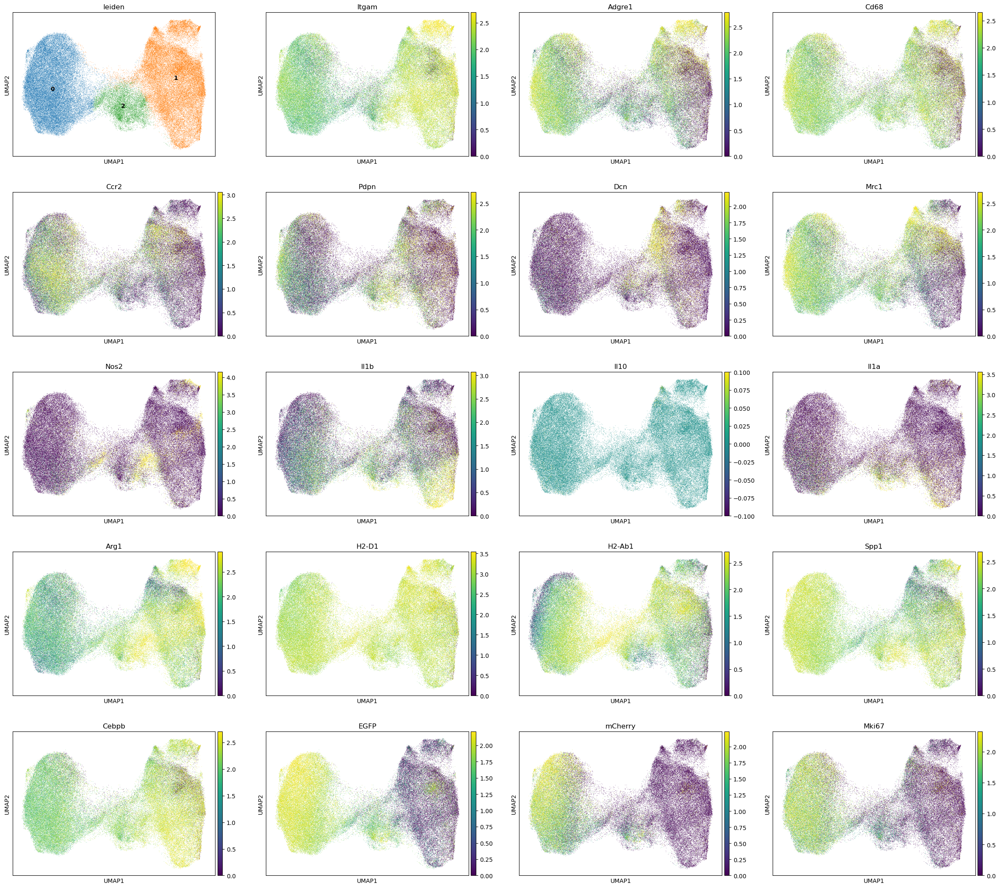

In [49]:
sc.pl.umap(macrophage_subset,color=['leiden',
                'Itgam', 'Adgre1', 'Cd68', 'Ccr2', 'Pdpn','Dcn','Mrc1', 'Nos2', 'Il1b', 'Il10', 'Il1a', 'Arg1','H2-D1','H2-Ab1','Spp1','Cebpb','EGFP', 'mCherry','Mki67'],
           legend_loc='on data',vmin=0,vmax='p95')

In [47]:
macrophage_subset = macrophage_subset[macrophage_subset.obs["leiden"].isin(['0','1','2','3','4','5'])].copy()
sc.pp.neighbors(macrophage_subset, use_rep="X_pca_harmony")
sc.tl.umap(macrophage_subset, min_dist=0.1)
sc.tl.leiden(macrophage_subset, resolution=0.3)

In [57]:
macrophage_subset.shape # 91044 macrophages 

(91044, 300)

In [50]:
# Add Macrophage leiden into xen data 
xen.obs.loc[macrophage_subset.obs_names,'Macrophage leiden'] = macrophage_subset.obs['leiden']
xen.obs.head()

,cell_id,x,y,cell_area,samp,condition,region,Tumor Core,Cell Type,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,n_counts,leiden,cell_type,Tumor leiden,Macrophage leiden
0,aaaahjjl-1,799.092346,6746.838379,191.236726,chemo1,chemo,Chemo reg2,Stroma,unknown,68,4.234107,181.0,5.204007,181.0,0,Stroma,NaN,NaN
1,aaaajiam-1,816.627136,6738.786133,88.099847,chemo1,chemo,Chemo reg2,Stroma,unknown,43,3.784190,88.0,4.488636,88.0,0,Macrophages,NaN,NaN
2,aaaajjfc-1,825.193665,6753.208496,210.608758,chemo1,chemo,Chemo reg2,Stroma,unknown,68,4.234107,256.0,5.549076,256.0,0,Macrophages,NaN,NaN
3,aaabbjll-1,814.940186,6746.884766,117.270786,chemo1,chemo,Chemo reg2,Stroma,unknown,58,4.077537,124.0,4.828314,124.0,1,B cells,NaN,NaN
4,aaabgicc-1,807.501282,6753.062012,136.733130,chemo1,chemo,Chemo reg2,Stroma,CD8,76,4.343805,197.0,5.288267,197.0,2,T cells,NaN,NaN


In [58]:
# Set cell_type from Macrophages to Stroma when Macrophage leiden = NaN
mask = (xen.obs['cell_type'] == 'Macrophages') & (xen.obs['Macrophage leiden'].isna())

# 3. Update the matching cells
xen.obs.loc[mask, 'cell_type'] = "Stroma"

/tmp/ipykernel_2121664/4046770745.py:11: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/tmp/ipykernel_2121664/4046770745.py:11: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/tmp/ipykernel_2121664/4046770745.py:11: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/tmp/ipykernel_2121664/4046770745.py:11: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/tmp/ipykernel_2121664/4046770745.py:11: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/tmp/ipykernel_2121664/4046770745.py:11: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


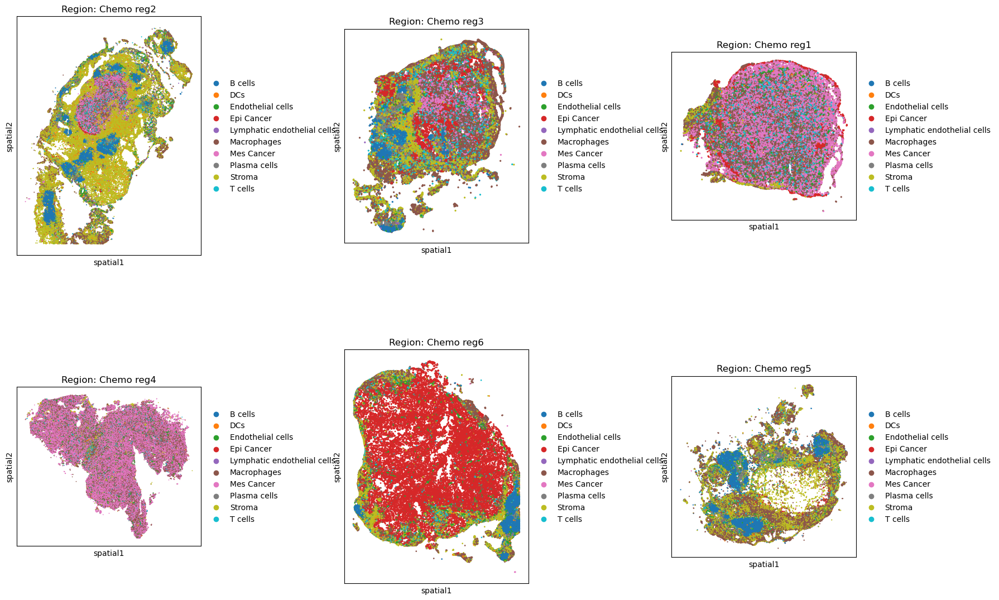

In [60]:
regs = xen.obs['region'].unique()
# Create a 2x3 grid of subplots
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for i, reg_id in enumerate(regs):
    # Subset data for just this region
    subset = xen[xen.obs["region"] == reg_id].copy()
    
    # Plot on its own dedicated subplot axis
    sc.pl.spatial(
        subset, 
        color="cell_type", 
        spot_size=30, 
        img_key=None, 
        ax=axes[i], 
        show=False,
        title=f"Region: {reg_id}"
    )

plt.tight_layout()
plt.savefig("./Xenium/Spatial Visulization cell_type.png", bbox_inches="tight",dpi=600)
plt.show()

In [62]:
# Label tumor regions vs. stroma
xen.obs.loc[xen.obs['cell_type'].isin(["Mes Cancer","Epi Cancer"]),'Tumor Core New'] = 'Intratumoral' 
TUMORRADIUS = 50
tum = xen[xen.obs['cell_type'].isin(["Mes Cancer","Epi Cancer"])]
from sklearn.neighbors import NearestNeighbors 
for reg in tqdm(xen.obs['region'].unique()): # Each slide is one region
    xen_reg = xen[xen.obs['region']==reg].obs # Get that slide
        
    tum_reg = tum[tum.obs['region']==reg].obs
    non_tum = xen_reg.drop(tum_reg.index,axis=0) # Remove tumor cells from all cells in Slide
    if len(tum_reg)==0: # If no tumor cells in Slide
        xen.obs.loc[non_tum.index,'Tumor Core New']='Stroma'
        continue

    cloud = tum_reg.loc[:,['x','y']].values # Get location of tumor cells
    tree = NearestNeighbors().fit(cloud) # Unsupervised for nearest neighbor searches

    pts = non_tum.loc[:,['x','y']].values # Location of non-tumor cells
    inds = tree.radius_neighbors(pts, radius=TUMORRADIUS, return_distance=False) #distance between tree and pts
    
    angles_all_pts = [np.arctan2(
        cloud[i,1] - A[1],
        cloud[i,0] - A[0]) for i,A in zip(inds,pts)]
    inside = []
    for angles in angles_all_pts: 
        if len(angles)<=1:
            inside+=[False]
        else:
            ang = np.sort(angles)
            gaps = np.diff(np.r_[ang, ang[0] + 2*np.pi])
            largest_gap = gaps.max()
            largest_gap_deg = largest_gap * 180 / np.pi # Convert radian to degree
            if np.abs(largest_gap_deg)>100: # If surrounded by tumor cells with largest angle < 100, considered intratumoral
                inside+=[False]
            else:
                inside+=[True]

    xen.obs.loc[non_tum.index,'Tumor Core New'] = [{True:'Intratumoral',False:'Stroma'}[i] for i in inside]

  0%|          | 0/6 [00:00<?, ?it/s]

In [63]:
xen.obs['Tumor Core New'].value_counts()

Tumor Core New
Stroma          206835
Intratumoral    170177
Name: count, dtype: int64

In [64]:
xen.write_h5ad("./Xenium/Graham_Chemo_Cell_Types.h5ad")

In [65]:
xen.obs.head()

,cell_id,x,y,cell_area,samp,condition,region,Tumor Core,Cell Type,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,n_counts,leiden,cell_type,Tumor leiden,Macrophage leiden,Tumor Core New
0,aaaahjjl-1,799.092346,6746.838379,191.236726,chemo1,chemo,Chemo reg2,Stroma,unknown,68,4.234107,181.0,5.204007,181.0,0,Stroma,NaN,NaN,Stroma
1,aaaajiam-1,816.627136,6738.786133,88.099847,chemo1,chemo,Chemo reg2,Stroma,unknown,43,3.784190,88.0,4.488636,88.0,0,Stroma,NaN,NaN,Stroma
2,aaaajjfc-1,825.193665,6753.208496,210.608758,chemo1,chemo,Chemo reg2,Stroma,unknown,68,4.234107,256.0,5.549076,256.0,0,Stroma,NaN,NaN,Stroma
3,aaabbjll-1,814.940186,6746.884766,117.270786,chemo1,chemo,Chemo reg2,Stroma,unknown,58,4.077537,124.0,4.828314,124.0,1,B cells,NaN,NaN,Stroma
4,aaabgicc-1,807.501282,6753.062012,136.733130,chemo1,chemo,Chemo reg2,Stroma,CD8,76,4.343805,197.0,5.288267,197.0,2,T cells,NaN,NaN,Stroma


In [66]:
for mask,mask_name in zip([xen.obs['cell_type']=='Epi Cancer',
                          xen.obs['cell_type']=='Mes Cancer'
                          ],['Epithelial','Mesenchymal']): # Each mask is a boolean
    xen.obs['{} Core'.format(mask_name)] = 'Intratumoral'

    TUMORRADIUS = 50
    tum = xen[mask] # Get those specific tumor cells
    from sklearn.neighbors import NearestNeighbors
    for reg in tqdm(xen.obs['region'].unique()): # Each slide is one region
        xen_reg = xen[xen.obs['region']==reg].obs # Get that slide
        
        tum_reg = tum[tum.obs['region']==reg].obs
        non_tum = xen_reg.drop(tum_reg.index,axis=0) # Remove tumor cells from all cells in Slide
        if len(tum_reg)==0: # If no tumor cells in Slide
            xen.obs.loc[non_tum.index,'{} Core'.format(mask_name)]='Stroma'
            continue

        cloud = tum_reg.loc[:,['x','y']].values # Get location of tumor cells
        tree = NearestNeighbors().fit(cloud) # Unsupervised for nearest neighbor searches

        pts = non_tum.loc[:,['x','y']].values # Location of non-tumor cells
        inds = tree.radius_neighbors(pts, radius=TUMORRADIUS, return_distance=False) #distance between tree and pts

        angles_all_pts = [np.arctan2(
            cloud[i,1] - A[1],
            cloud[i,0] - A[0]) for i,A in zip(inds,pts)]
        inside = []
        for angles in angles_all_pts: 
            if len(angles)<=1:
                inside+=[False]
            else:
                ang = np.sort(angles)
                gaps = np.diff(np.r_[ang, ang[0] + 2*np.pi])
                largest_gap = gaps.max()
                largest_gap_deg = largest_gap * 180 / np.pi # Convert radian to degree
                if np.abs(largest_gap_deg)>100: # If surrounded by tumor cells with largest angle < 100, considered intratumoral
                    inside+=[False]
                else:
                    inside+=[True]

        xen.obs.loc[non_tum.index,'{} Core'.format(mask_name)] = [{True:'Intratumoral',
                                                       False:'Stroma'}[i] for i in inside]

  0%|          | 0/6 [00:00<?, ?it/s]

  0%|          | 0/6 [00:00<?, ?it/s]

In [69]:
print(xen.obs['Epithelial Core'].value_counts())
xen.obs['Mesenchymal Core'].value_counts()

Epithelial Core
Stroma          342553
Intratumoral     34459
Name: count, dtype: int64


Mesenchymal Core
Stroma          242270
Intratumoral    134742
Name: count, dtype: int64

In [70]:
xen.obs[['Macrophage leiden','Tumor Core New']].value_counts()

Macrophage leiden  Tumor Core New
1                  Stroma            39406
0                  Intratumoral      36702
2                  Stroma             5813
0                  Stroma             4676
2                  Intratumoral       2827
1                  Intratumoral       1620
Name: count, dtype: int64

In [71]:
xen.write_h5ad("./Xenium/Graham_Chemo_Cell_Types.h5ad")

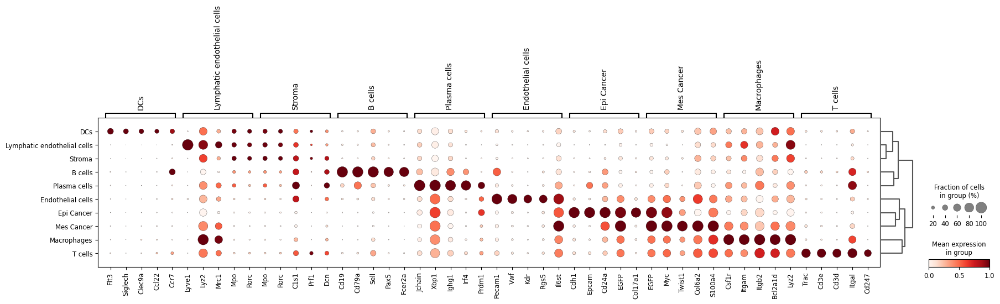

In [74]:
# Macrophage infiltration, in Epi, Mes, and Stromal regions 
# Get number and frequency of macrophages in each compartment 
sc.tl.rank_genes_groups(xen, groupby="cell_type", layer="lognorm", pts=True)
sc.pl.rank_genes_groups_dotplot(xen, n_genes=5, show=False, standard_scale='var')
plt.savefig("./Xenium/Cell_Type_Marker_dotplot.png", bbox_inches="tight",dpi=600)